# AlphaWind Park – Asset Performance Investigation

## 1. Data Loading and Validation

The objective of this section is to load the four datasets, inspect
their structure and validate the consistency of timestamps,
observations and operational records.

The analysis covers 1–7 March 2026, with production and weather
measurements recorded at 10-minute intervals.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

# Current Jupyter working directory
DATA_DIR = Path(".")

# Load datasets
production = pd.read_csv(DATA_DIR / "production.csv")
weather = pd.read_csv(DATA_DIR / "weather.csv")
stops = pd.read_csv(DATA_DIR / "stops_log.csv")
metadata = pd.read_csv(DATA_DIR / "turbine_metadata.csv")

# Convert timestamps
production["timestamp"] = pd.to_datetime(production["timestamp"])
weather["timestamp"] = pd.to_datetime(weather["timestamp"])

stops["timestamp_start"] = pd.to_datetime(stops["timestamp_start"])
stops["timestamp_end"] = pd.to_datetime(stops["timestamp_end"])

print("All datasets loaded successfully.")
print("Working directory:", Path.cwd())

All datasets loaded successfully.
Working directory: C:\Users\marty


### 1.2 Dataset overview

Inspect the dimensions, columns, data types and first observations
of each dataset to understand the available information.

In [3]:
datasets = {
    "Production": production,
    "Weather": weather,
    "Stops log": stops,
    "Turbine metadata": metadata
}

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(name.upper())
    print(f"{'='*60}")
    print(f"Shape: {df.shape}")
    print("\nColumns and data types:")
    print(df.dtypes)
    print("\nFirst observations:")
    display(df.head())


PRODUCTION
Shape: (6048, 3)

Columns and data types:
timestamp     datetime64[ns]
turbine_id            object
energy_kwh           float64
dtype: object

First observations:


,timestamp,turbine_id,energy_kwh
0,2026-03-01 00:00:00,T01,81.98
1,2026-03-01 00:10:00,T01,104.79
2,2026-03-01 00:20:00,T01,94.30
3,2026-03-01 00:30:00,T01,132.86
4,2026-03-01 00:40:00,T01,237.53



WEATHER
Shape: (1008, 2)

Columns and data types:
timestamp        datetime64[ns]
wind_speed_ms           float64
dtype: object

First observations:


,timestamp,wind_speed_ms
0,2026-03-01 00:00:00,8.33
1,2026-03-01 00:10:00,9.00
2,2026-03-01 00:20:00,8.78
3,2026-03-01 00:30:00,9.67
4,2026-03-01 00:40:00,11.85



STOPS LOG
Shape: (38, 5)

Columns and data types:
timestamp_start    datetime64[ns]
timestamp_end      datetime64[ns]
turbine_id                 object
stop_code                  object
comment                    object
dtype: object

First observations:


,timestamp_start,timestamp_end,turbine_id,stop_code,comment
0,2026-03-02 01:30:00,2026-03-02 03:00:00,T02,FLT,Hydraulic technical fault #1
1,2026-03-02 06:40:00,2026-03-02 08:10:00,T04,FLT,Hydraulic technical fault #1
2,2026-03-03 11:50:00,2026-03-03 14:50:00,T06,MTN,Scheduled maintenance
3,2026-03-03 23:20:00,2026-03-04 00:50:00,T03,FLT,Hydraulic technical fault #1
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation



TURBINE METADATA
Shape: (6, 5)

Columns and data types:
turbine_id               object
park                     object
country                  object
model                    object
last_service_days_ago     int64
dtype: object

First observations:


,turbine_id,park,country,model,last_service_days_ago
0,T01,AlphaWind,LT,V112,12
1,T02,AlphaWind,LT,V112,40
2,T03,AlphaWind,LT,V112,5
3,T04,AlphaWind,LT,V112,120
4,T05,AlphaWind,LT,V112,18


### 1.3 Data quality checks

Check the following:

- Missing values.
- Duplicate observations.
- Timestamp coverage.
- Negative or zero production values.
- Wind speed measurement ranges.
- Consistency of turbine identifiers.

In [4]:
# 1. Missing values
for name, df in datasets.items():
    print(f"\n{name} – Missing values")
    display(df.isnull().sum().to_frame("Missing values"))

# 2. Duplicate observations
print("\nDuplicate records:")
print("Production:", production.duplicated().sum())
print("Weather:", weather.duplicated().sum())
print("Stops log:", stops.duplicated().sum())
print("Metadata:", metadata.duplicated().sum())

# 3. Timestamp coverage
for name, df, col in [
    ("Production", production, "timestamp"),
    ("Weather", weather, "timestamp"),
    ("Stops log", stops, "timestamp_start")
]:
    print(f"\n{name}")
    print("Start:", df[col].min())
    print("End:", df[col].max())
    print("Unique timestamps:", df[col].nunique())

# 4. Production validation
print("\nProduction statistics:")
display(production["energy_kwh"].describe())

print("Negative production observations:",
      (production["energy_kwh"] < 0).sum())

print("Zero production observations:",
      (production["energy_kwh"] == 0).sum())

# 5. Weather validation
print("\nWind speed statistics:")
display(weather["wind_speed_ms"].describe())

print("Negative wind speed observations:",
      (weather["wind_speed_ms"] < 0).sum())

# 6. Turbine identifiers
print("\nProduction observations per turbine:")
display(production.groupby("turbine_id").size())

print("\nMetadata:")
display(metadata)


Production – Missing values


,Missing values
timestamp,0
turbine_id,0
energy_kwh,0



Weather – Missing values


,Missing values
timestamp,0
wind_speed_ms,0



Stops log – Missing values


,Missing values
timestamp_start,0
timestamp_end,4
turbine_id,0
stop_code,0
comment,0


... (6 outputs left out)

Negative wind speed observations: 0

Production observations per turbine:


turbine_id
T01    1008
T02    1008
T03    1008
T04    1008
T05    1008
T06    1008
dtype: int64


Metadata:


,turbine_id,park,country,model,last_service_days_ago
0,T01,AlphaWind,LT,V112,12
1,T02,AlphaWind,LT,V112,40
2,T03,AlphaWind,LT,V112,5
3,T04,AlphaWind,LT,V112,120
4,T05,AlphaWind,LT,V112,18
5,T06,AlphaWind,LT,V112,65


### 1.4 Production coverage and zero-production patterns

Investigate how zero-production observations are distributed
across turbines and days.

This provides an initial indication of operational interruptions
and differences in turbine behaviour.

,Zero observations,Total observations,Zero percentage
turbine_id,,,
T01,96,1008,9.52
T02,96,1008,9.52
T03,93,1008,9.23
T04,120,1008,11.90
T05,96,1008,9.52
T06,104,1008,10.32


,Zero observations
date,
2026-03-01,130
2026-03-02,18
2026-03-03,22
2026-03-04,201
2026-03-05,40
2026-03-06,149
2026-03-07,45


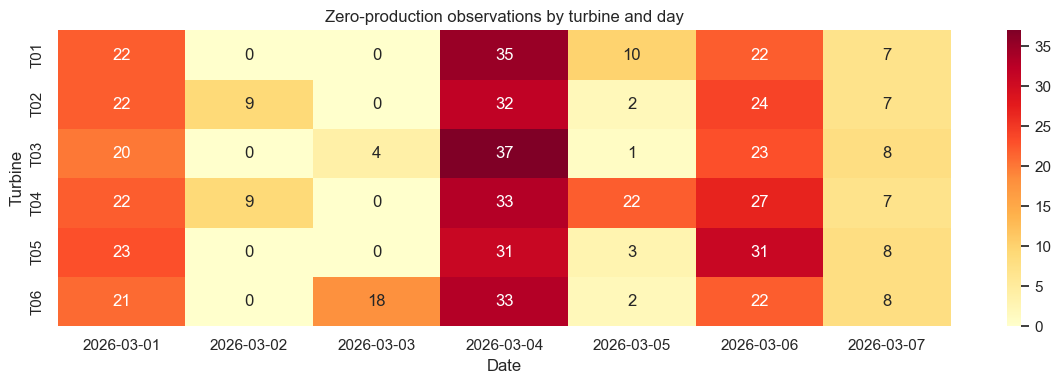

In [5]:
# Extract date
production["date"] = production["timestamp"].dt.date

# Zero-production observations per turbine
zero_by_turbine = (
    production.assign(is_zero=production["energy_kwh"] == 0)
    .groupby("turbine_id")["is_zero"]
    .agg(["sum", "count", "mean"])
)

zero_by_turbine.columns = [
    "Zero observations",
    "Total observations",
    "Zero percentage"
]

zero_by_turbine["Zero percentage"] *= 100

display(zero_by_turbine.round(2))

# Zero-production observations per day
zero_by_day = (
    production.assign(is_zero=production["energy_kwh"] == 0)
    .groupby("date")["is_zero"]
    .sum()
)

display(zero_by_day.to_frame("Zero observations"))

# Visualise zero production by turbine and date
zero_pivot = (
    production.assign(is_zero=(production["energy_kwh"] == 0))
    .pivot_table(
        index="turbine_id",
        columns="date",
        values="is_zero",
        aggfunc="sum"
    )
)

plt.figure(figsize=(12, 4))
sns.heatmap(zero_pivot, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Zero-production observations by turbine and day")
plt.xlabel("Date")
plt.ylabel("Turbine")
plt.tight_layout()
plt.show()

### 1.5 Operational event data quality

The operational event log may contain duplicate records,
missing end timestamps and incomplete turbine-level reporting
of park-wide events.

Before using these records for energy loss attribution,
we need to understand their structure and identify
potential inconsistencies.

In [6]:
# Event counts by type
print("Events by type:")
display(stops["stop_code"].value_counts().to_frame("Number of records"))

# Missing event end timestamps
print("\nMissing event end timestamps:")
display(stops[stops["timestamp_end"].isna()])

# Exact duplicate records
print("\nDuplicate event records:")
display(stops[stops.duplicated(keep=False)].sort_values(
    ["timestamp_start", "stop_code", "turbine_id"]
))

# Event counts by turbine
print("\nEvents by turbine:")
display(pd.crosstab(stops["turbine_id"], stops["stop_code"]))

# Event durations (hours)
stops["duration_hours"] = (
    stops["timestamp_end"] - stops["timestamp_start"]
).dt.total_seconds() / 3600

print("\nRecorded event durations:")
display(
    stops.groupby("stop_code")["duration_hours"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

Events by type:


,Number of records
stop_code,
GRD,17
WND,12
FLT,7
MTN,2



Missing event end timestamps:


,timestamp_start,timestamp_end,turbine_id,stop_code,comment
9,2026-03-04 09:00:00,NaT,T06,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,NaT,T03,GRD,Park-level grid limitation
22,2026-03-06 14:40:00,NaT,T04,WND,High wind shutdown
24,2026-03-06 14:40:00,NaT,T06,WND,High wind shutdown



Duplicate event records:


,timestamp_start,timestamp_end,turbine_id,stop_code,comment
26,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation
27,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation



Events by turbine:


stop_code,FLT,GRD,MTN,WND
turbine_id,,,,
T01,1,4,0,2
T02,1,2,0,2
T03,1,3,0,2
T04,3,3,1,2
T05,1,3,0,2
T06,0,2,1,2



Recorded event durations:


,count,mean,min,max
stop_code,,,,
FLT,7,1.57,1.50,2.00
GRD,15,2.00,2.00,2.00
MTN,2,3.00,3.00,3.00
WND,10,1.73,1.00,2.83


## 2. Exploratory Data Analysis

### 2.1 Park-level production and weather

I aggregate individual turbine production to the park level
and combine it with the corresponding wind-speed measurements.

I investigate daily production, average wind speed and the
relationship between wind conditions and energy generation.

In [7]:
# Aggregate production across all six turbines
park_production = (
    production.groupby("timestamp")["energy_kwh"]
    .sum()
    .reset_index(name="park_energy_kwh")
)

# Merge with park-level weather data
park_data = park_production.merge(
    weather,
    on="timestamp",
    how="inner"
)

# Daily performance summary
daily_summary = (
    park_data.groupby(park_data["timestamp"].dt.date)
    .agg(
        daily_energy_kwh=("park_energy_kwh", "sum"),
        avg_wind_speed_ms=("wind_speed_ms", "mean"),
        max_wind_speed_ms=("wind_speed_ms", "max"),
        min_wind_speed_ms=("wind_speed_ms", "min")
    )
    .reset_index()
    .rename(columns={"timestamp": "date"})
)

display(daily_summary.round(2))

# Overall park statistics
print("Total park production:",
      round(park_data["park_energy_kwh"].sum(), 2), "kWh")

print("Average park production per 10-minute interval:",
      round(park_data["park_energy_kwh"].mean(), 2), "kWh")

print("Average wind speed:",
      round(park_data["wind_speed_ms"].mean(), 2), "m/s")

,date,daily_energy_kwh,avg_wind_speed_ms,max_wind_speed_ms,min_wind_speed_ms
0,2026-03-01,"48,232.13",6.41,14.16,1.66
1,2026-03-02,"117,981.44",10.35,20.09,4.06
2,2026-03-03,"135,936.78",11.37,20.10,4.95
3,2026-03-04,"30,096.00",5.47,15.83,1.01
4,2026-03-05,"79,282.52",8.56,20.24,2.56
5,2026-03-06,"79,905.96",12.06,27.21,1.60
6,2026-03-07,"150,894.21",14.64,27.24,3.66


Total park production: 642329.04 kWh
Average park production per 10-minute interval: 637.23 kWh
Average wind speed: 9.84 m/s


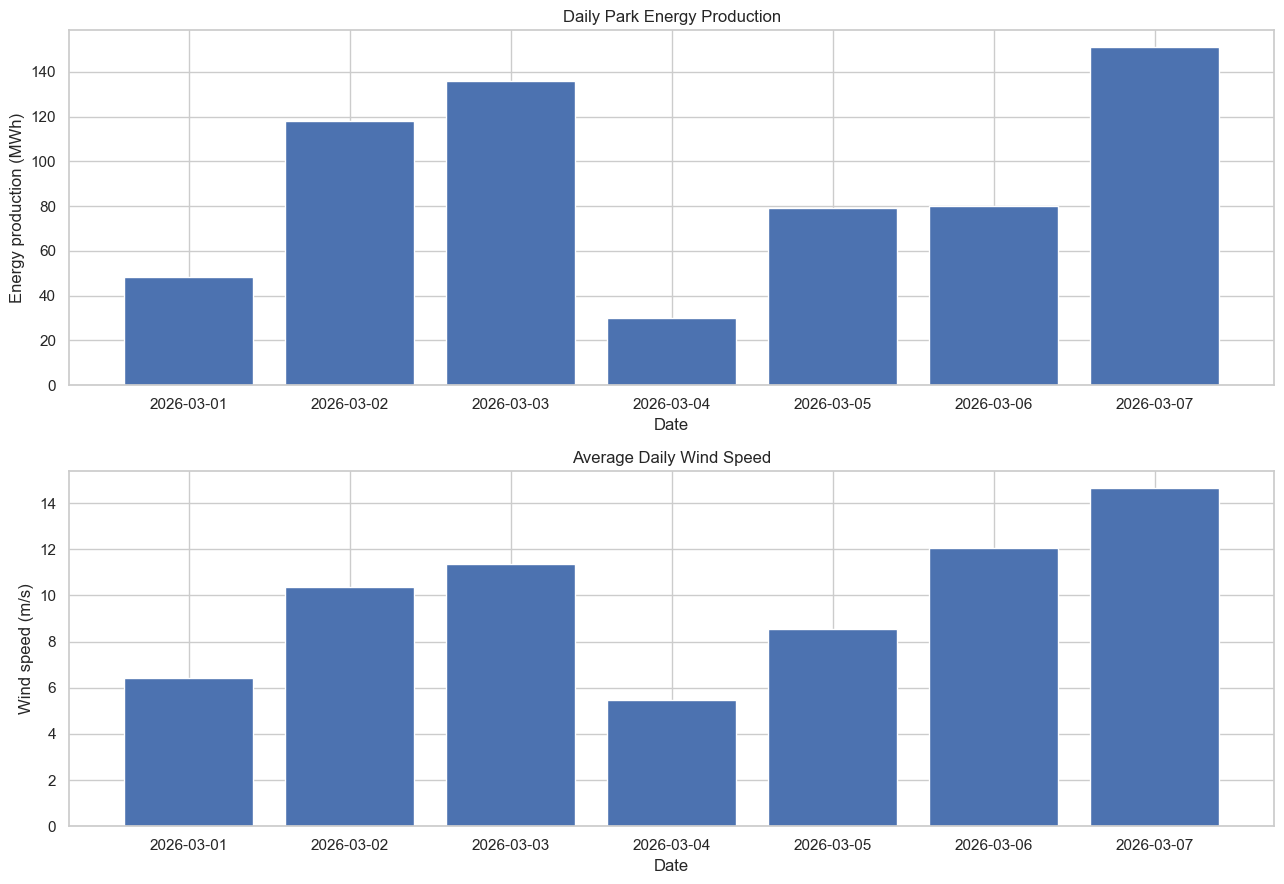

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Daily energy production
axes[0].bar(
    daily_summary["date"].astype(str),
    daily_summary["daily_energy_kwh"] / 1000
)

axes[0].set_title("Daily Park Energy Production")
axes[0].set_ylabel("Energy production (MWh)")
axes[0].set_xlabel("Date")

# Average daily wind speed
axes[1].bar(
    daily_summary["date"].astype(str),
    daily_summary["avg_wind_speed_ms"]
)

axes[1].set_title("Average Daily Wind Speed")
axes[1].set_ylabel("Wind speed (m/s)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

### 2.3 Intraday production patterns

I examine park production and wind speed at 10-minute intervals
to identify sudden production reductions and their relationship
with changing weather conditions.

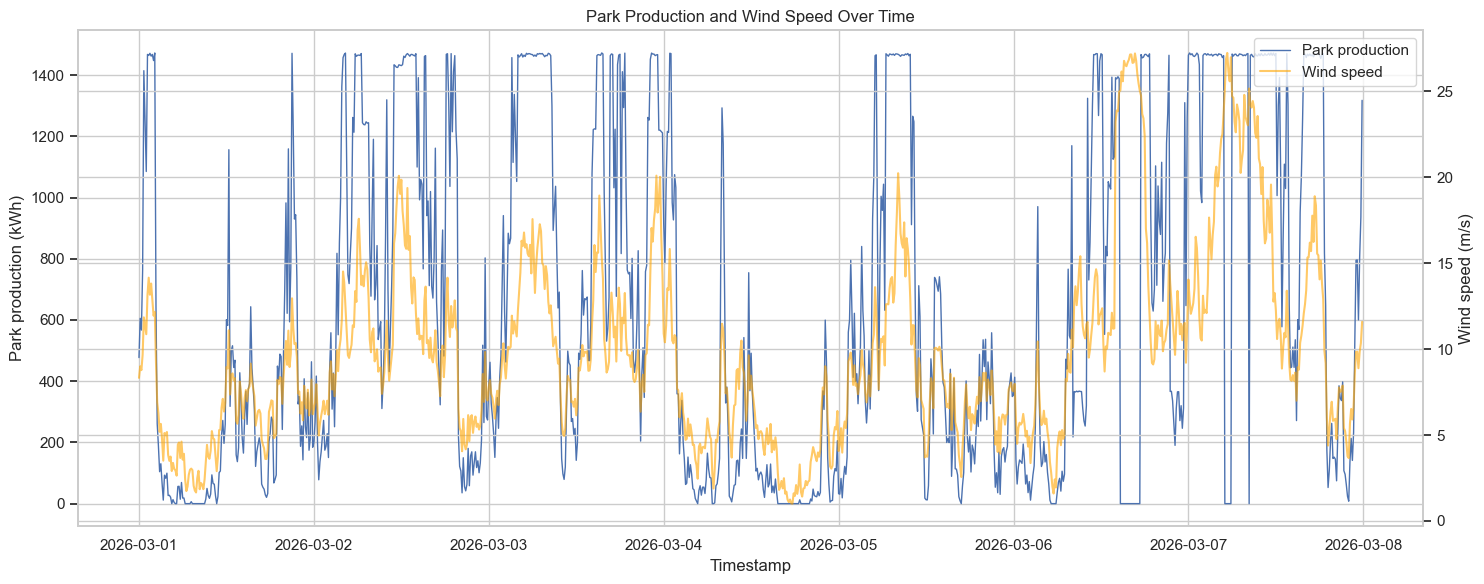

In [9]:
fig, ax1 = plt.subplots(figsize=(15, 6))

# Park production
ax1.plot(
    park_data["timestamp"],
    park_data["park_energy_kwh"],
    label="Park production",
    linewidth=1
)

ax1.set_xlabel("Timestamp")
ax1.set_ylabel("Park production (kWh)")
ax1.set_title("Park Production and Wind Speed Over Time")

# Wind speed on secondary axis
ax2 = ax1.twinx()

ax2.plot(
    park_data["timestamp"],
    park_data["wind_speed_ms"],
    color="orange",
    alpha=0.6,
    label="Wind speed"
)

ax2.set_ylabel("Wind speed (m/s)")

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 2.4 Turbine-level production comparison

I compare total and average energy production across the six turbines.

The turbines have identical models and share the same park-level
wind measurements. Therefore, systematic differences in production
may indicate differences in operational performance.

In [10]:
# Calculate turbine-level production statistics
turbine_summary = (
    production.groupby("turbine_id")
    .agg(
        total_energy_kwh=("energy_kwh", "sum"),
        avg_energy_kwh=("energy_kwh", "mean"),
        median_energy_kwh=("energy_kwh", "median"),
        max_energy_kwh=("energy_kwh", "max"),
        zero_observations=("energy_kwh", lambda x: (x == 0).sum())
    )
    .reset_index()
)

# Add maintenance information
turbine_summary = turbine_summary.merge(
    metadata[["turbine_id", "last_service_days_ago"]],
    on="turbine_id",
    how="left"
)

# Calculate production relative to the park average per turbine
park_avg = turbine_summary["total_energy_kwh"].mean()

turbine_summary["relative_to_average_pct"] = (
    (turbine_summary["total_energy_kwh"] / park_avg - 1) * 100
)

display(turbine_summary.round(2))

,turbine_id,total_energy_kwh,avg_energy_kwh,median_energy_kwh,max_energy_kwh,zero_observations,last_service_days_ago,relative_to_average_pct
0,T01,"110,801.04",109.92,79.18,250.00,96,12,3.50
1,T02,"108,414.95",107.55,77.32,246.25,96,40,1.27
2,T03,"109,405.85",108.54,76.78,251.25,93,5,2.20
3,T04,"96,571.86",95.81,65.82,225.00,120,120,-9.79
4,T05,"109,694.77",108.82,77.47,252.50,96,18,2.47
5,T06,"107,440.57",106.59,74.64,247.50,104,65,0.36


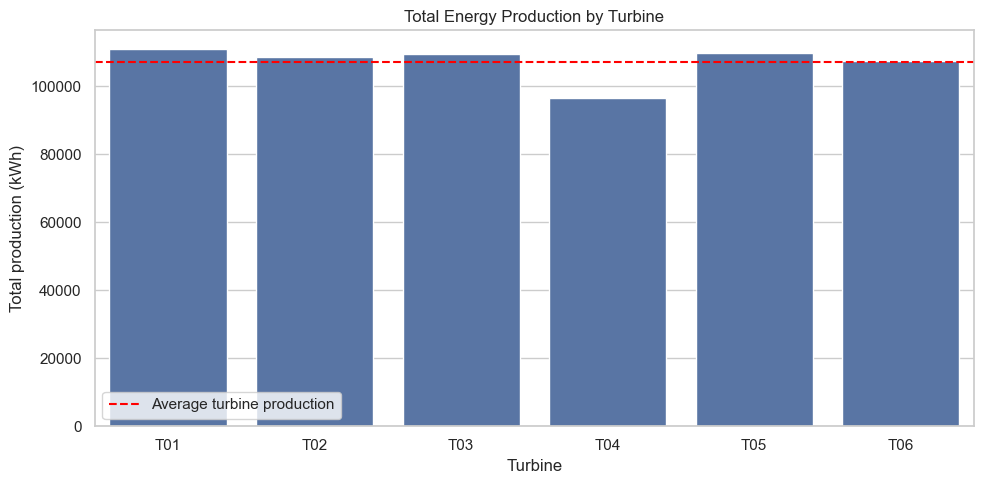

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=turbine_summary,
    x="turbine_id",
    y="total_energy_kwh"
)

plt.axhline(
    park_avg,
    color="red",
    linestyle="--",
    label="Average turbine production"
)

plt.title("Total Energy Production by Turbine")
plt.xlabel("Turbine")
plt.ylabel("Total production (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

### 2.5 Production performance by wind-speed range

I compare turbine production under similar wind conditions.

Grouping observations into wind-speed intervals allows us to
identify turbines that consistently produce less energy than
their peers under comparable conditions.

In [12]:
# Merge wind speed into individual turbine observations
turbine_weather = production.merge(
    weather,
    on="timestamp",
    how="inner"
)

# Define wind-speed intervals
wind_bins = [0, 3, 5, 7, 9, 11, 13, 15, 20, 25, 30]

wind_labels = [
    "0-3", "3-5", "5-7", "7-9", "9-11",
    "11-13", "13-15", "15-20", "20-25", "25-30"
]

turbine_weather["wind_range"] = pd.cut(
    turbine_weather["wind_speed_ms"],
    bins=wind_bins,
    labels=wind_labels,
    include_lowest=True
)

# Average production per turbine and wind-speed interval
wind_performance = (
    turbine_weather.groupby(
        ["wind_range", "turbine_id"],
        observed=True
    )["energy_kwh"]
    .mean()
    .reset_index()
)

# Pivot for easier comparison
wind_comparison = wind_performance.pivot(
    index="wind_range",
    columns="turbine_id",
    values="energy_kwh"
)

display(wind_comparison.round(2))

turbine_id,T01,T02,T03,T04,T05,T06
wind_range,,,,,,
0-3,0.00,0.00,0.00,0.00,0.00,0.00
3-5,6.97,6.92,7.58,5.95,7.04,7.02
5-7,28.38,27.55,28.62,24.56,28.95,28.16
7-9,73.31,69.80,72.86,62.97,73.49,69.45
9-11,137.39,135.78,137.12,117.56,132.68,131.57
11-13,213.61,210.22,212.86,191.93,207.67,206.77
13-15,234.41,230.80,223.68,193.14,236.63,227.93
15-20,246.99,240.35,242.26,219.56,249.58,241.63
20-25,249.01,244.05,244.04,223.94,244.20,246.43


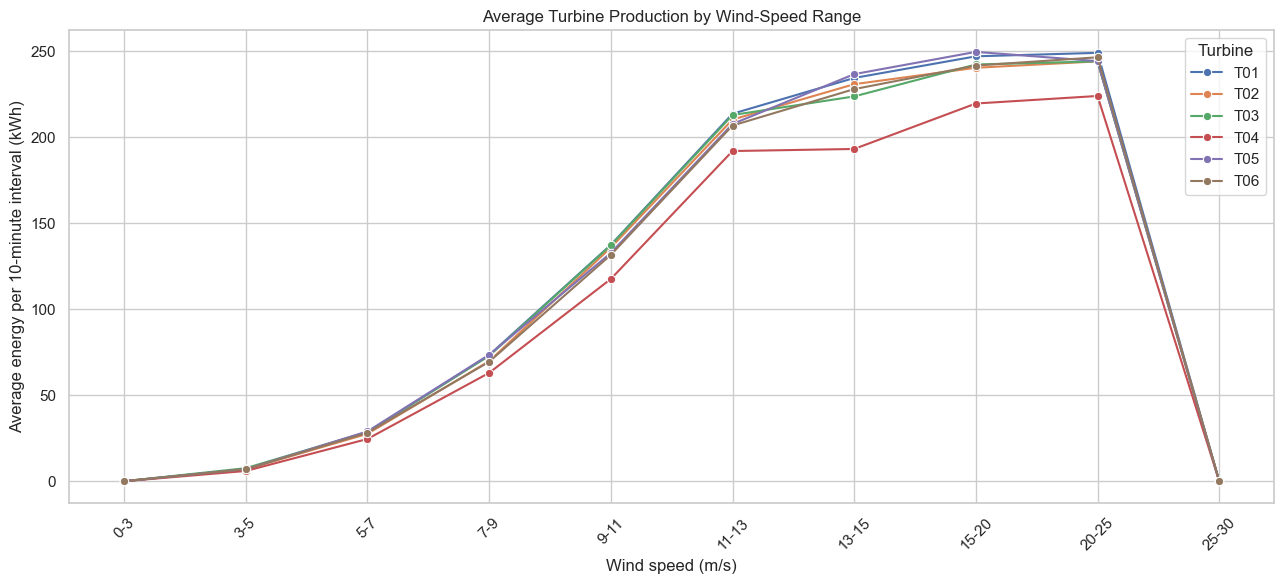

In [13]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=wind_performance,
    x="wind_range",
    y="energy_kwh",
    hue="turbine_id",
    marker="o"
)

plt.title("Average Turbine Production by Wind-Speed Range")
plt.xlabel("Wind speed (m/s)")
plt.ylabel("Average energy per 10-minute interval (kWh)")
plt.xticks(rotation=45)
plt.legend(title="Turbine")
plt.tight_layout()
plt.show()

## 3. Expected Production Baseline

### 3.1 Preparation of reference observations

I want to construct a reference dataset using the five turbines other
than T04.

I remove observations affected by recorded operational events.
For park-level events (WND and GRD), exclude the corresponding
time intervals across all turbines.

For turbine-level events (FLT and MTN), I exclude only the
affected turbine observations.

Where event end timestamps are missing, I attempt to reconstruct
them using other records with the same event type and start time.

The resulting dataset will be used to estimate a common
reference production curve.

In [14]:
# Remove exact duplicate event records
events_clean = stops.drop_duplicates().copy()

# Reconstruct missing end timestamps using matching event records
for idx, event in events_clean[events_clean["timestamp_end"].isna()].iterrows():

    matching_events = events_clean[
        (events_clean["timestamp_start"] == event["timestamp_start"]) &
        (events_clean["stop_code"] == event["stop_code"]) &
        (events_clean["timestamp_end"].notna())
    ]

    if not matching_events.empty:
        events_clean.loc[idx, "timestamp_end"] = (
            matching_events["timestamp_end"].max()
        )

print("Remaining missing event end timestamps:",
      events_clean["timestamp_end"].isna().sum())

display(events_clean.sort_values("timestamp_start"))

Remaining missing event end timestamps: 0


,timestamp_start,timestamp_end,turbine_id,stop_code,comment,duration_hours
0,2026-03-02 01:30:00,2026-03-02 03:00:00,T02,FLT,Hydraulic technical fault #1,1.50
1,2026-03-02 06:40:00,2026-03-02 08:10:00,T04,FLT,Hydraulic technical fault #1,1.50
2,2026-03-03 11:50:00,2026-03-03 14:50:00,T06,MTN,Scheduled maintenance,3.00
3,2026-03-03 23:20:00,2026-03-04 00:50:00,T03,FLT,Hydraulic technical fault #1,1.50
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation,2.00
5,2026-03-04 09:00:00,2026-03-04 11:00:00,T02,GRD,Park-level grid limitation,2.00
6,2026-03-04 09:00:00,2026-03-04 11:00:00,T03,GRD,Park-level grid limitation,2.00
7,2026-03-04 09:00:00,2026-03-04 11:00:00,T04,GRD,Park-level grid limitation,2.00
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,Park-level grid limitation,2.00
9,2026-03-04 09:00:00,2026-03-04 11:00:00,T06,GRD,Park-level grid limitation,NaN


In [15]:
# Combine production and weather
turbine_weather = production.merge(
    weather,
    on="timestamp",
    how="inner"
)

# Create event indicator
turbine_weather["recorded_event"] = False

# Park-level events: apply to all turbines
park_events = events_clean[
    events_clean["stop_code"].isin(["WND", "GRD"])
]

# Consolidate park-level events by event type and start time
park_events = (
    park_events.groupby(
        ["stop_code", "timestamp_start"],
        as_index=False
    )["timestamp_end"]
    .max()
)

for _, event in park_events.iterrows():

    mask = (
        (turbine_weather["timestamp"] >= event["timestamp_start"]) &
        (turbine_weather["timestamp"] < event["timestamp_end"])
    )

    turbine_weather.loc[mask, "recorded_event"] = True


# Turbine-level events: apply only to affected turbines
turbine_events = events_clean[
    events_clean["stop_code"].isin(["FLT", "MTN"])
]

for _, event in turbine_events.iterrows():

    mask = (
        (turbine_weather["turbine_id"] == event["turbine_id"]) &
        (turbine_weather["timestamp"] >= event["timestamp_start"]) &
        (turbine_weather["timestamp"] < event["timestamp_end"])
    )

    turbine_weather.loc[mask, "recorded_event"] = True


# Summary of observations excluded from the reference dataset
print("Total turbine observations:",
      len(turbine_weather))

print("Observations affected by recorded events:",
      turbine_weather["recorded_event"].sum())

print("Observations without recorded events:",
      (~turbine_weather["recorded_event"]).sum())

Total turbine observations: 6048
Observations affected by recorded events: 456
Observations without recorded events: 5592


In [16]:
# Select reference turbines
reference_turbines = ["T01", "T02", "T03", "T05", "T06"]

reference_data = turbine_weather[
    (~turbine_weather["recorded_event"]) &
    (turbine_weather["turbine_id"].isin(reference_turbines)) &
    (turbine_weather["wind_speed_ms"] < 25)
].copy()

# Define wind-speed intervals
wind_bins = [0, 3, 5, 7, 9, 11, 13, 15, 20, 25]

wind_labels = [
    "0-3", "3-5", "5-7", "7-9",
    "9-11", "11-13", "13-15", "15-20", "20-25"
]

reference_data["wind_range"] = pd.cut(
    reference_data["wind_speed_ms"],
    bins=wind_bins,
    labels=wind_labels,
    include_lowest=True
)

# Estimate median production for each wind-speed interval
reference_curve = (
    reference_data.groupby("wind_range", observed=False)
    ["energy_kwh"]
    .agg(["median", "mean", "count"])
    .reset_index()
)

display(reference_curve.round(2))

,wind_range,median,mean,count
0,0-3,0.00,0.00,275
1,3-5,7.16,7.22,563
2,5-7,28.00,29.15,884
3,7-9,74.00,73.87,790
4,9-11,139.90,143.61,770
5,11-13,240.28,230.81,469
6,13-15,248.54,248.36,291
7,15-20,248.58,247.96,432
8,20-25,247.83,246.72,209


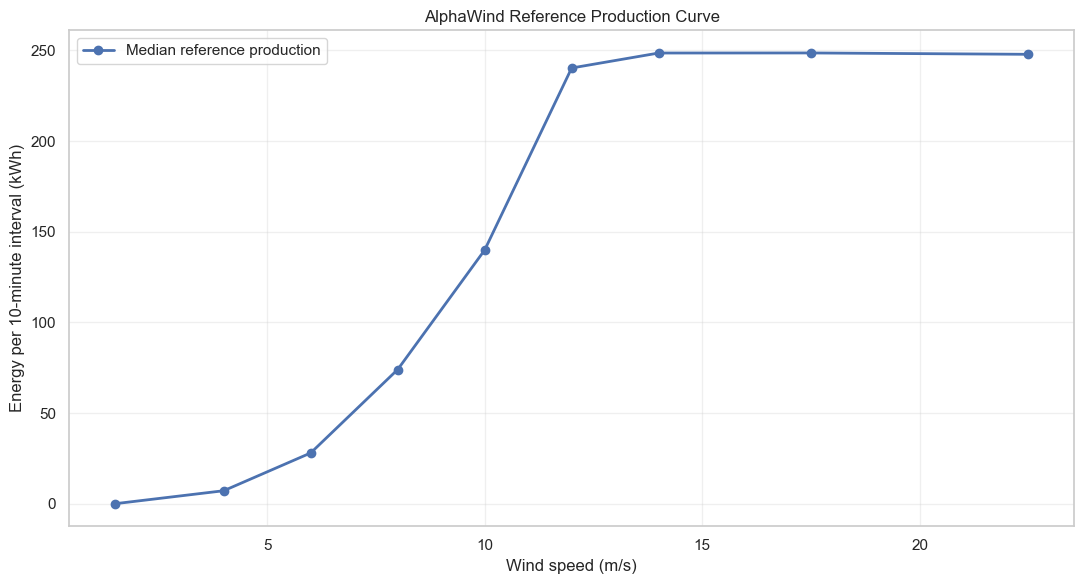

In [17]:
# Calculate wind-speed interval midpoints
bin_midpoints = np.array([
    1.5, 4, 6, 8, 10, 12, 14, 17.5, 22.5
])

plt.figure(figsize=(11, 6))

plt.plot(
    bin_midpoints,
    reference_curve["median"],
    marker="o",
    linewidth=2,
    label="Median reference production"
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Energy per 10-minute interval (kWh)")
plt.title("AlphaWind Reference Production Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Extract reference curve values
curve_values = reference_curve["median"].to_numpy()

# Check for missing wind-speed intervals
if np.isnan(curve_values).any():
    raise ValueError(
        "Reference curve contains empty wind-speed intervals. "
        "Inspect the reference_curve table before proceeding."
    )

# Interpolate expected production
all_wind_speeds = turbine_weather["wind_speed_ms"].to_numpy()

expected_production = np.interp(
    all_wind_speeds,
    bin_midpoints,
    curve_values
)

# Apply operating limits
expected_production[all_wind_speeds < 3] = 0
expected_production[all_wind_speeds >= 25] = 0

# Add expected production to the dataset
turbine_weather["expected_kwh"] = expected_production

# Calculate positive production shortfalls
turbine_weather["potential_loss_kwh"] = (
    turbine_weather["expected_kwh"] -
    turbine_weather["energy_kwh"]
).clip(lower=0)

# Calculate production deviations
turbine_weather["production_deviation_kwh"] = (
    turbine_weather["energy_kwh"] -
    turbine_weather["expected_kwh"]
)

display(
    turbine_weather[
        ["timestamp", "turbine_id", "wind_speed_ms",
         "energy_kwh", "expected_kwh",
         "potential_loss_kwh"]
    ].head(15).round(2)
)

,timestamp,turbine_id,wind_speed_ms,energy_kwh,expected_kwh,potential_loss_kwh
0,2026-03-01 00:00:00,T01,8.33,81.98,84.87,2.89
1,2026-03-01 00:10:00,T01,9.00,104.79,106.95,2.16
2,2026-03-01 00:20:00,T01,8.78,94.30,99.70,5.40
3,2026-03-01 00:30:00,T01,9.67,132.86,129.03,0.00
4,2026-03-01 00:40:00,T01,11.85,237.53,232.75,0.00
5,2026-03-01 00:50:00,T01,11.35,207.26,207.66,0.40
6,2026-03-01 01:00:00,T01,10.87,185.36,183.57,0.00
7,2026-03-01 01:10:00,T01,13.16,250.00,245.07,0.00
8,2026-03-01 01:20:00,T01,14.16,250.00,248.54,0.00
9,2026-03-01 01:30:00,T01,13.17,248.85,245.11,0.00


In [19]:
# Aggregate actual and expected production at park level
park_baseline = (
    turbine_weather.groupby("timestamp")
    .agg(
        actual_kwh=("energy_kwh", "sum"),
        expected_kwh=("expected_kwh", "sum"),
        potential_loss_kwh=("potential_loss_kwh", "sum"),
        wind_speed_ms=("wind_speed_ms", "first")
    )
    .reset_index()
)

# Daily baseline comparison
daily_baseline = (
    park_baseline.groupby(park_baseline["timestamp"].dt.date)
    .agg(
        actual_kwh=("actual_kwh", "sum"),
        expected_kwh=("expected_kwh", "sum"),
        potential_loss_kwh=("potential_loss_kwh", "sum")
    )
    .reset_index()
    .rename(columns={"timestamp": "date"})
)

daily_baseline["production_ratio_pct"] = (
    daily_baseline["actual_kwh"] /
    daily_baseline["expected_kwh"] * 100
)

display(daily_baseline.round(2))

print("Total actual production:",
      round(park_baseline["actual_kwh"].sum(), 2), "kWh")

print("Total expected production:",
      round(park_baseline["expected_kwh"].sum(), 2), "kWh")

print("Gross potential production shortfall:",
      round(park_baseline["potential_loss_kwh"].sum(), 2), "kWh")

,date,actual_kwh,expected_kwh,potential_loss_kwh,production_ratio_pct
0,2026-03-01,"48,232.13","50,821.80","3,004.08",94.90
1,2026-03-02,"117,981.44","123,316.63","6,328.25",95.67
2,2026-03-03,"135,936.78","141,828.34","7,058.38",95.85
3,2026-03-04,"30,096.00","36,933.10","7,098.77",81.49
4,2026-03-05,"79,282.52","83,956.78","5,238.63",94.43
5,2026-03-06,"79,905.96","106,773.15","27,551.75",74.84
6,2026-03-07,"150,894.21","153,196.49","3,523.63",98.50


Total actual production: 642329.04 kWh
Total expected production: 696826.3 kWh
Gross potential production shortfall: 59803.49 kWh


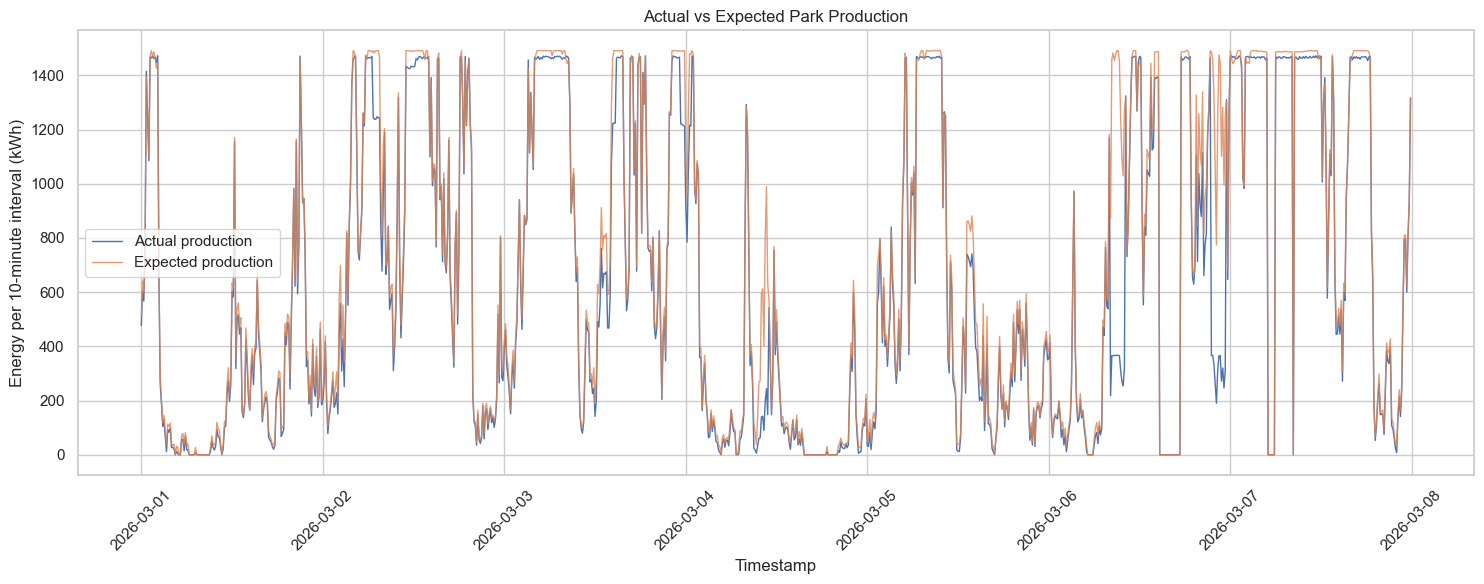

In [20]:
plt.figure(figsize=(15, 6))

plt.plot(
    park_baseline["timestamp"],
    park_baseline["actual_kwh"],
    label="Actual production",
    linewidth=1
)

plt.plot(
    park_baseline["timestamp"],
    park_baseline["expected_kwh"],
    label="Expected production",
    linewidth=1,
    alpha=0.8
)

plt.title("Actual vs Expected Park Production")
plt.xlabel("Timestamp")
plt.ylabel("Energy per 10-minute interval (kWh)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
turbine_baseline = (
    turbine_weather.groupby("turbine_id")
    .agg(
        actual_kwh=("energy_kwh", "sum"),
        expected_kwh=("expected_kwh", "sum"),
        potential_loss_kwh=("potential_loss_kwh", "sum")
    )
    .reset_index()
)

turbine_baseline["production_ratio_pct"] = (
    turbine_baseline["actual_kwh"] /
    turbine_baseline["expected_kwh"] * 100
)

display(turbine_baseline.round(2))

,turbine_id,actual_kwh,expected_kwh,potential_loss_kwh,production_ratio_pct
0,T01,"110,801.04","116,137.72","6,452.30",95.40
1,T02,"108,414.95","116,137.72","8,129.66",93.35
2,T03,"109,405.85","116,137.72","8,187.77",94.20
3,T04,"96,571.86","116,137.72","19,570.60",83.15
4,T05,"109,694.77","116,137.72","8,265.61",94.45
5,T06,"107,440.57","116,137.72","9,197.55",92.51


### 3.6 Reference baseline validation

I examine the distribution of production observations used to
construct the reference curve.

I compare production across reference turbines within each
wind-speed interval and investigate the large increase in
median production between the 9–11 and 11–13 m/s intervals.

This helps assess whether the reference curve represents
a reasonably consistent operating pattern.

In [22]:
# Production distribution by wind-speed interval and turbine
reference_diagnostics = (
    reference_data.groupby(
        ["wind_range", "turbine_id"],
        observed=True
    )["energy_kwh"]
    .agg(
        count="count",
        median="median",
        mean="mean",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

display(reference_diagnostics.round(2))

,wind_range,turbine_id,count,median,mean,q25,q75
0,0-3,T01,55,0.00,0.00,0.00,0.00
1,0-3,T02,55,0.00,0.00,0.00,0.00
2,0-3,T03,55,0.00,0.00,0.00,0.00
3,0-3,T05,55,0.00,0.00,0.00,0.00
4,0-3,T06,55,0.00,0.00,0.00,0.00
5,3-5,T01,111,6.68,7.17,3.36,10.30
6,3-5,T02,113,6.87,7.00,3.80,10.27
7,3-5,T03,113,8.22,7.69,4.64,10.62
8,3-5,T05,113,7.03,7.13,3.13,11.03
9,3-5,T06,113,6.92,7.12,3.22,10.58


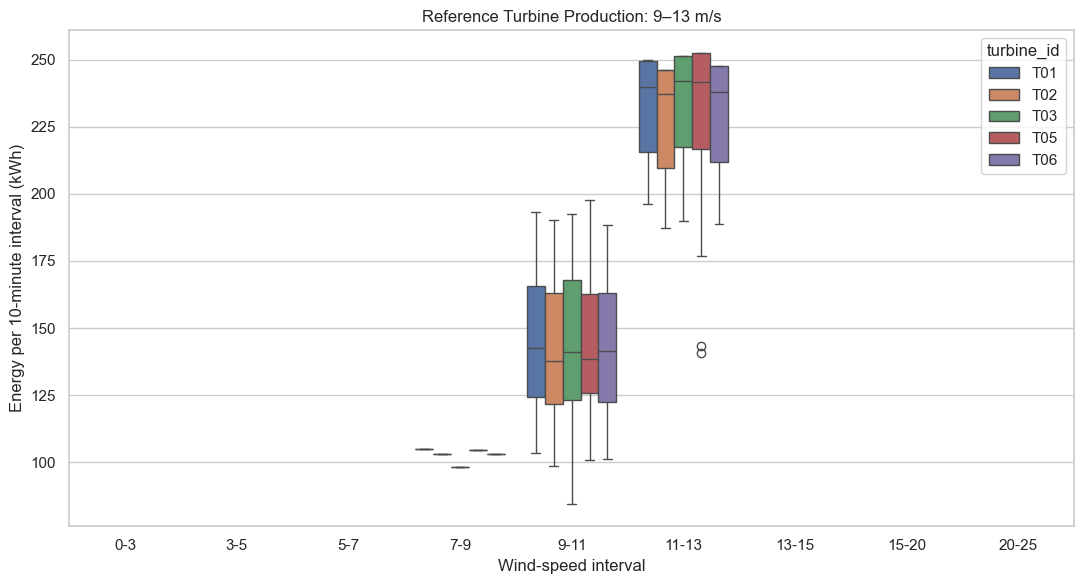

In [23]:
# Detailed observations between 9 and 13 m/s
mid_wind_data = reference_data[
    (reference_data["wind_speed_ms"] >= 9) &
    (reference_data["wind_speed_ms"] < 13)
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=mid_wind_data,
    x="wind_range",
    y="energy_kwh",
    hue="turbine_id"
)

plt.title("Reference Turbine Production: 9–13 m/s")
plt.xlabel("Wind-speed interval")
plt.ylabel("Energy per 10-minute interval (kWh)")
plt.tight_layout()
plt.show()

### 3.7 Baseline fit check

If the reference curve represents normal operation well, the difference between
actual and expected production on the reference data itself should be close to
zero in every wind-speed interval. A consistent positive or negative residual
in an interval means the curve is biased there.

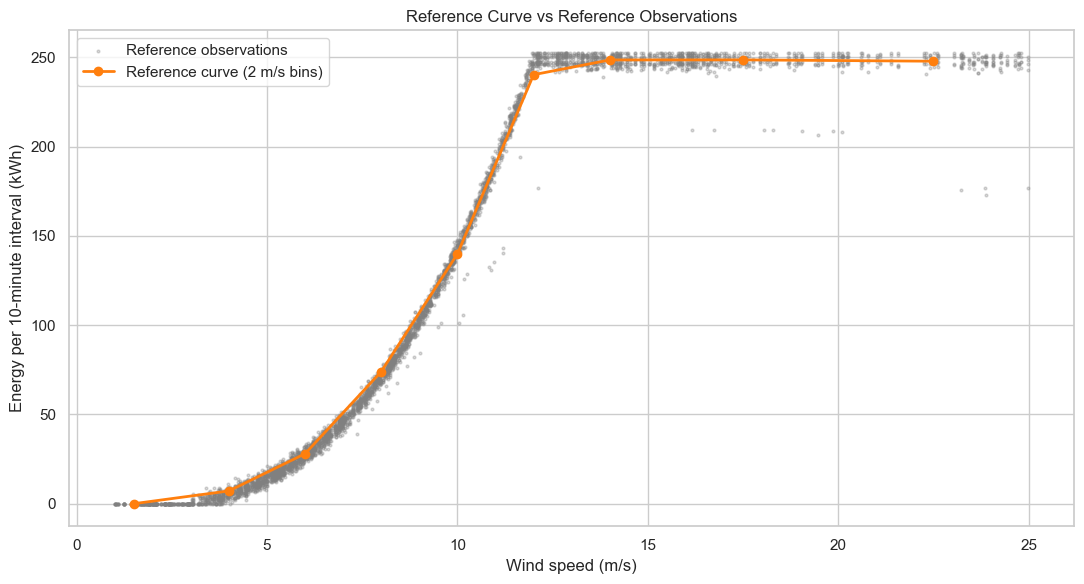

In [24]:
plt.figure(figsize=(11, 6))

plt.scatter(
    reference_data["wind_speed_ms"],
    reference_data["energy_kwh"],
    s=4, alpha=0.3, color="grey",
    label="Reference observations"
)

plt.plot(
    bin_midpoints,
    reference_curve["median"],
    marker="o", linewidth=2, color="tab:orange",
    label="Reference curve (2 m/s bins)"
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Energy per 10-minute interval (kWh)")
plt.title("Reference Curve vs Reference Observations")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Apply the current curve to the reference data it was built from
reference_data["expected_kwh"] = np.interp(
    reference_data["wind_speed_ms"],
    bin_midpoints,
    reference_curve["median"]
)
reference_data.loc[reference_data["wind_speed_ms"] < 3, "expected_kwh"] = 0

reference_data["residual_kwh"] = (
    reference_data["energy_kwh"] - reference_data["expected_kwh"]
)

residual_by_bin = (
    reference_data.groupby("wind_range", observed=True)["residual_kwh"]
    .agg(mean_residual="mean", total_residual="sum", count="count")
)

display(residual_by_bin.round(2))

print("Total residual on reference data:",
      round(reference_data["residual_kwh"].sum(), 1), "kWh")
print("As % of reference production:",
      round(reference_data["residual_kwh"].sum()
            / reference_data["energy_kwh"].sum() * 100, 2), "%")

,mean_residual,total_residual,count
wind_range,,,
0-3,0.00,0.00,275
3-5,-2.92,"-1,642.73",563
5-7,-2.57,"-2,276.06",884
7-9,-4.32,"-3,413.10",790
9-11,-0.36,-276.91,770
11-13,4.65,"2,181.32",469
13-15,1.00,290.52,291
15-20,-0.56,-241.18,432
20-25,-1.20,-250.02,209


Total residual on reference data: -5628.2 kWh
As % of reference production: -1.05 %


### 3.8 Refined reference curve

The fit check shows a systematic pattern: the 2 m/s curve overestimates at
3–9 m/s and underestimates at 11–13 m/s. Linear interpolation between wide-bin
midpoints cannot follow the curvature of the power curve.

The curve is rebuilt with 0.5 m/s bins using the method of bins described in
IEC 61400-12-1 (the standard for power-curve measurement). This is not a
compliant power-performance test: there is no met mast, air-density correction
or wind-direction filtering, and only one week of data. It is used here only
as a consistent internal baseline for comparing turbines and estimating losses.

In [50]:
BIN_WIDTH = 0.5

reference_data["fine_bin"] = (
    (reference_data["wind_speed_ms"] / BIN_WIDTH).round() * BIN_WIDTH
)

fine_curve = (
    reference_data.groupby("fine_bin")["energy_kwh"]
    .agg(mean="mean", median="median", count="count")
)

# Drop sparse bins; interpolation covers the gaps
fine_curve = fine_curve[fine_curve["count"] >= 10]

display(fine_curve.round(1).T)


def expected_from_curve(wind_speed):
    """Expected 10-minute energy for a normally operating turbine."""
    ws = np.asarray(wind_speed, dtype=float)
    expected = np.interp(ws, fine_curve.index.values, fine_curve["mean"].values)
    expected[ws >= 25] = 0      # cut-out
    return expected

fine_bin,1.00,1.50,2.00,2.50,3.00,3.50,4.00,4.50,5.00,5.50,6.00,6.50,7.00,7.50,8.00,8.50,9.00,9.50,10.00,10.50,11.00,11.50,12.00,12.50,13.00,13.50,14.00,14.50,15.00,15.50,16.00,16.50,17.00,17.50,18.00,18.50,19.00,19.50,20.00,20.50,21.00,21.50,22.50,23.00,23.50,24.00,24.50,25.00
mean,0.00,0.00,0.00,0.00,0.50,2.80,5.30,9.40,14.50,20.50,27.90,36.40,45.70,57.90,71.60,85.80,102.90,122.10,141.20,166.10,188.00,217.10,245.00,248.70,248.70,248.30,248.50,248.30,248.20,248.50,248.20,248.50,247.70,248.40,247.60,246.50,247.20,247.00,246.70,248.80,248.50,248.50,248.50,244.90,247.60,243.70,248.00,243.20
median,0.00,0.00,0.00,0.00,0.00,2.80,5.20,9.50,14.60,20.60,27.70,36.70,45.80,57.80,71.60,86.00,103.50,122.40,140.30,166.20,187.40,217.40,246.40,249.00,249.20,248.80,249.10,248.30,247.50,248.60,248.40,249.00,249.00,248.10,248.50,247.30,249.40,249.80,250.00,247.80,249.10,247.90,249.20,249.70,247.50,247.50,247.40,247.20
count,25.00,50.00,90.00,65.00,80.00,105.00,149.00,164.00,215.00,212.00,240.00,189.00,202.00,188.00,219.00,217.00,191.00,184.00,223.00,177.00,157.00,155.00,115.00,85.00,84.00,103.00,75.00,63.00,45.00,55.00,104.00,59.00,45.00,40.00,30.00,19.00,25.00,20.00,34.00,15.00,15.00,10.00,25.00,20.00,25.00,35.00,20.00,15.00


,2 m/s bins (median),0.5 m/s bins (mean)
wind_range,,
0-3,0.00,-0.07
3-5,-2.92,-0.16
5-7,-2.57,-0.11
7-9,-4.32,-0.28
9-11,-0.36,0.08
11-13,4.65,1.49
13-15,1.00,-0.04
15-20,-0.56,-0.03
20-25,-1.20,-0.06


2 m/s curve - total residual: -5,628.2 kWh (-1.05 %)
0.5 m/s curve - total residual: 295.5 kWh (0.05 %)


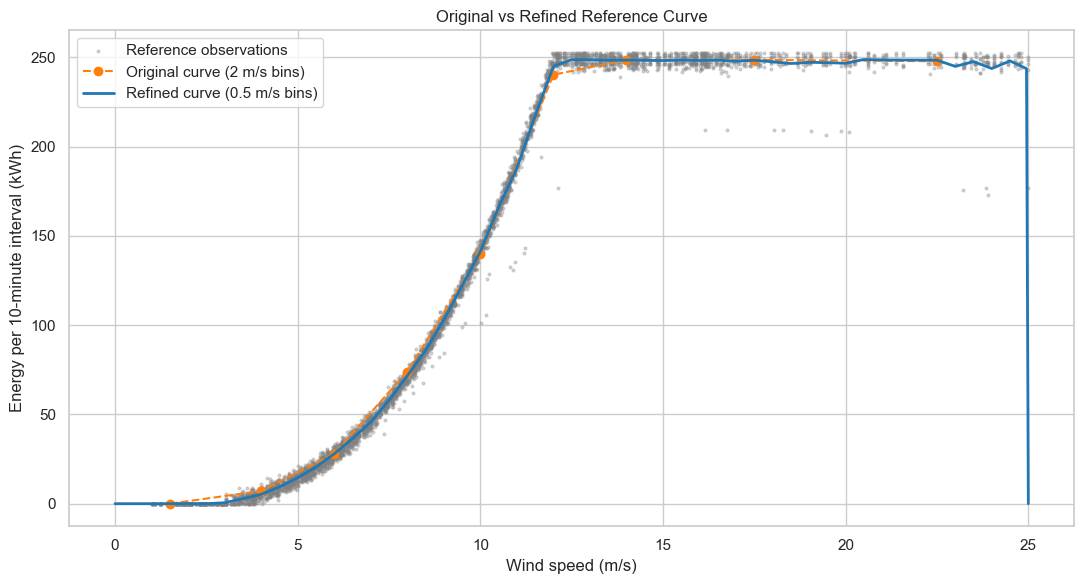

In [27]:
reference_data["expected_fine_kwh"] = expected_from_curve(reference_data["wind_speed_ms"])
reference_data["residual_fine_kwh"] = (
    reference_data["energy_kwh"] - reference_data["expected_fine_kwh"]
)

residual_comparison = pd.DataFrame({
    "2 m/s bins (median)":
        reference_data.groupby("wind_range", observed=True)["residual_kwh"].mean(),
    "0.5 m/s bins (mean)":
        reference_data.groupby("wind_range", observed=True)["residual_fine_kwh"].mean()
})
display(residual_comparison.round(2))

for col, label in [("residual_kwh", "2 m/s"), ("residual_fine_kwh", "0.5 m/s")]:
    total = reference_data[col].sum()
    print(f"{label} curve - total residual: {total:,.1f} kWh "
          f"({total / reference_data['energy_kwh'].sum() * 100:.2f} %)")

# Visual comparison
xs = np.linspace(0, 25, 500)
plt.figure(figsize=(11, 6))
plt.scatter(reference_data["wind_speed_ms"], reference_data["energy_kwh"],
            s=4, alpha=0.3, color="grey", label="Reference observations")
plt.plot(bin_midpoints, reference_curve["median"], "o--", color="tab:orange",
         label="Original curve (2 m/s bins)")
plt.plot(xs, expected_from_curve(xs), linewidth=2, color="tab:blue",
         label="Refined curve (0.5 m/s bins)")
plt.xlabel("Wind speed (m/s)")
plt.ylabel("Energy per 10-minute interval (kWh)")
plt.title("Original vs Refined Reference Curve")
plt.legend()
plt.tight_layout()
plt.show()

### 3.9 Updated expected production

The refined curve replaces the 2 m/s curve for all further analysis.
Expected production is recalculated for every turbine and interval.

Two loss measures are shown:
- *Net deviation*: sum of (expected − actual). Small positive and negative
  deviations during normal operation cancel out.
- *Gross shortfall*: sum of positive deviations only (the approach used in 3.3).
  This also counts random noise as "loss", so it overstates the true loss.

Net deviation is used from here on.

In [28]:
# Recalculate expected production with the refined curve
turbine_weather["expected_kwh"] = expected_from_curve(turbine_weather["wind_speed_ms"])
turbine_weather["deviation_kwh"] = (
    turbine_weather["expected_kwh"] - turbine_weather["energy_kwh"]
)
# Overwrite the old column so it is not used by mistake later
turbine_weather["potential_loss_kwh"] = turbine_weather["deviation_kwh"].clip(lower=0)

# Park level
park_baseline = (
    turbine_weather.groupby("timestamp")
    .agg(actual_kwh=("energy_kwh", "sum"),
         expected_kwh=("expected_kwh", "sum"),
         wind_speed_ms=("wind_speed_ms", "first"))
    .reset_index()
)

# Daily
daily_baseline = (
    turbine_weather.groupby(turbine_weather["timestamp"].dt.date)
    .agg(actual_kwh=("energy_kwh", "sum"),
         expected_kwh=("expected_kwh", "sum"),
         net_deviation_kwh=("deviation_kwh", "sum"),
         gross_shortfall_kwh=("potential_loss_kwh", "sum"))
)
daily_baseline["performance_ratio_pct"] = (
    daily_baseline["actual_kwh"] / daily_baseline["expected_kwh"] * 100
)
display(daily_baseline.round(1))

# Turbine level
turbine_baseline = (
    turbine_weather.groupby("turbine_id")
    .agg(actual_kwh=("energy_kwh", "sum"),
         expected_kwh=("expected_kwh", "sum"),
         net_deviation_kwh=("deviation_kwh", "sum"))
)
turbine_baseline["performance_ratio_pct"] = (
    turbine_baseline["actual_kwh"] / turbine_baseline["expected_kwh"] * 100
)
display(turbine_baseline.round(1))

print(f"Total expected:          {turbine_weather['expected_kwh'].sum():,.0f} kWh")
print(f"Total actual:            {turbine_weather['energy_kwh'].sum():,.0f} kWh")
print(f"Net deviation:           {turbine_weather['deviation_kwh'].sum():,.0f} kWh")
print(f"Gross shortfall (old):   {turbine_weather['potential_loss_kwh'].sum():,.0f} kWh")

,actual_kwh,expected_kwh,net_deviation_kwh,gross_shortfall_kwh,performance_ratio_pct
timestamp,,,,,
2026-03-01,"48,232.10","49,060.90",828.80,"1,495.00",98.30
2026-03-02,"117,981.40","122,533.40","4,552.00","5,543.50",96.30
2026-03-03,"135,936.80","141,157.00","5,220.20","6,299.50",96.30
2026-03-04,"30,096.00","35,284.30","5,188.30","5,789.30",85.30
2026-03-05,"79,282.50","82,328.00","3,045.50","3,837.00",96.30
2026-03-06,"79,906.00","106,463.70","26,557.70","27,276.90",75.10
2026-03-07,"150,894.20","152,854.10","1,959.90","3,051.10",98.70


,actual_kwh,expected_kwh,net_deviation_kwh,performance_ratio_pct
turbine_id,,,,
T01,"110,801.00","114,946.90","4,145.90",96.40
T02,"108,415.00","114,946.90","6,531.90",94.30
T03,"109,405.80","114,946.90","5,541.00",95.20
T04,"96,571.90","114,946.90","18,375.00",84.00
T05,"109,694.80","114,946.90","5,252.10",95.40
T06,"107,440.60","114,946.90","7,506.30",93.50


Total expected:          689,681 kWh
Total actual:            642,329 kWh
Net deviation:           47,352 kWh
Gross shortfall (old):   53,292 kWh


## 4. Operational Event Log: Validation and Cleaning

### 4.1 Validating log records against production

The stop log is not fully reliable, so I check each record against the
production data:

- A *stop* (WND, FLT, MTN) should show zero production for its full duration.
- A *grid limitation* (GRD) should show reduced but non-zero production.
- A *park-level event* (WND, GRD) should be recorded for all six turbines.

In [29]:
event_check = []

for _, e in events_clean.sort_values("timestamp_start").iterrows():
    window = turbine_weather[
        (turbine_weather["turbine_id"] == e["turbine_id"]) &
        (turbine_weather["timestamp"] >= e["timestamp_start"]) &
        (turbine_weather["timestamp"] < e["timestamp_end"])
    ]

    event_check.append({
        "start": e["timestamp_start"],
        "end": e["timestamp_end"],
        "turbine_id": e["turbine_id"],
        "stop_code": e["stop_code"],
        "hours": len(window) / 6,
        "mean_wind_ms": window["wind_speed_ms"].mean(),
        "actual_kwh": window["energy_kwh"].sum(),
        "expected_kwh": window["expected_kwh"].sum(),
        "zero_share_pct": (window["energy_kwh"] == 0).mean() * 100,
    })

event_check = pd.DataFrame(event_check)
event_check["output_vs_expected_pct"] = (
    event_check["actual_kwh"] / event_check["expected_kwh"] * 100
)

display(event_check.round(1))

,start,end,turbine_id,stop_code,hours,mean_wind_ms,actual_kwh,expected_kwh,zero_share_pct,output_vs_expected_pct
0,2026-03-02 01:30:00,2026-03-02 03:00:00,T02,FLT,1.50,7.50,0.00,552.80,100.00,0.00
1,2026-03-02 06:40:00,2026-03-02 08:10:00,T04,FLT,1.50,13.00,0.00,"1,981.20",100.00,0.00
2,2026-03-03 11:50:00,2026-03-03 14:50:00,T06,MTN,3.00,9.90,0.00,"2,385.90",100.00,0.00
3,2026-03-03 23:20:00,2026-03-04 00:50:00,T03,FLT,1.50,14.40,0.00,"2,041.30",100.00,0.00
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,2.00,7.30,201.60,789.80,0.00,25.50
5,2026-03-04 09:00:00,2026-03-04 11:00:00,T02,GRD,2.00,7.30,194.30,789.80,0.00,24.60
6,2026-03-04 09:00:00,2026-03-04 11:00:00,T03,GRD,2.00,7.30,192.40,789.80,0.00,24.40
7,2026-03-04 09:00:00,2026-03-04 11:00:00,T04,GRD,2.00,7.30,179.00,789.80,0.00,22.70
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,2.00,7.30,199.40,789.80,0.00,25.20
9,2026-03-04 09:00:00,2026-03-04 11:00:00,T06,GRD,2.00,7.30,195.60,789.80,0.00,24.80


In [31]:
# How many records does each park-level event have per turbine?
park_coverage = (
    events_clean[events_clean["stop_code"].isin(["WND", "GRD"])]
    .pivot_table(
        index=["stop_code", "timestamp_start"],
        columns="turbine_id",
        values="comment",
        aggfunc="count",
        fill_value=0
    )
    .reindex(columns=sorted(production["turbine_id"].unique()), fill_value=0)
)

display(park_coverage)

turbine_id                     T01  T02  T03  T04  T05  T06
stop_code timestamp_start                                  
GRD       2026-03-04 09:00:00    1    1    1    1    1    1
          2026-03-06 08:10:00    1    0    1    1    1    1
          2026-03-06 21:30:00    1    1    1    1    1    0
WND       2026-03-06 14:40:00    1    1    1    1    1    1
          2026-03-07 05:00:00    1    1    1    1    1    1

### 4.1 Findings

*Turbine-level stops (FLT, MTN)*
- All records show 100% zero production during the logged period, except one:
  the *T01 fault on 5 March (00:10–02:10)* shows only 75% zero intervals, and
  T01 produced 307.7 kWh inside the logged stop. The turbine was back online
  about 30 minutes before the event was closed in the log, so the logged
  duration is too long.
- Not every logged event costs energy. The *T04 fault on 4 March (15:50–17:20)*
  occurred at a mean wind speed of 1.8 m/s, when expected production was 0 kWh.
  The *T04 fault on 6 March (05:10–06:40)* occurred at 3.3 m/s and cost about
  47 kWh. T04 has the most fault records (3), but only one had a material energy
  impact. Event counts alone overstate the importance of low-wind events.

*Grid limitations (GRD)*
- All three grid events show reduced but non-zero production. They are output
  limitations, not full stops.
- In every event the turbines produced about *25% of expected output*, which
  points to a park export limit at roughly a quarter of capacity.
- T04 produced the least in every grid event (179, 601 and 568 kWh vs ~190–675 kWh
  for its peers). Its ~10% production gap persists even under an external
  output cap (examined further in Section 6).

*High-wind shutdowns (WND)*
- Both WND events show 100% zero production at mean wind speeds above 26 m/s,
  consistent with a cut-out at 25 m/s.
- Expected production during these events is 0 kWh, because the reference curve
  sets expected output to zero above cut-out. Under this convention, high-wind
  shutdowns show no energy loss. This is addressed in the loss attribution stage.

*Completeness of park-level reporting*
- Two park-level events are not recorded for all six turbines:
  - *GRD, 6 March 08:10:* no record for *T02*
  - *GRD, 6 March 21:30:* no record for *T06*
- If these records are not added, the losses from these turbines during the
  grid events would wrongly appear as unexplained.

*Implications for cleaning*
1. Turbine-level events must be checked against production, and their end
   times corrected where the turbine restarted earlier than logged.
2. Missing park-level records must be added, but only where production
   confirms the turbine was affected by the event.

### 4.2 Cleaning rules

Findings from 4.1 lead to two additional corrections (on top of duplicate removal
and end-time reconstruction in 3.1):

| Rule | Issue | Correction |
|---|---|---|
| A | Turbine-level event logged longer than the actual stop (T01 FLT, 5 Mar) | End trimmed to the first interval where the turbine produces > 50% of its peers |
| B | Park-level event missing for some turbines (T02 and T06 GRD, 6 Mar) | Record added *only if* the turbine's production shows it was curtailed like its peers |

Every correction is recorded in a correction column so it can be traced.

In [32]:
# Wide format: one column per turbine, for peer comparisons
prod_wide = production.pivot(index="timestamp", columns="turbine_id", values="energy_kwh")

def peer_median(turbine):
    """Median production of the other five turbines at each timestamp."""
    return prod_wide.drop(columns=turbine).median(axis=1)

# Rule B check: during each incomplete park event, did the unrecorded turbine
# produce like its curtailed peers (ratio ~1), or normally (ratio >> 1)?
for (code, start), row in park_coverage.iterrows():
    missing_turbines = row[row == 0].index
    end = events_clean[(events_clean["stop_code"] == code) &
                       (events_clean["timestamp_start"] == start)]["timestamp_end"].max()
    for t in missing_turbines:
        window = prod_wide.loc[start: end - pd.Timedelta("10min")]
        ratio = (window[t] / window.drop(columns=t).median(axis=1)).median()
        print(f"{code} {start} – {t} not logged. Output vs curtailed peers: {ratio:.2f}")

GRD 2026-03-06 08:10:00 – T02 not logged. Output vs curtailed peers: 0.99
GRD 2026-03-06 21:30:00 – T06 not logged. Output vs curtailed peers: 1.00


In [34]:
events_final = events_clean.copy()
events_final["logged_end"] = stops.loc[events_final.index, "timestamp_end"]   # original log value
events_final["correction"] = np.where(
    events_final["logged_end"].isna(),
    "End time reconstructed from sibling park records", ""
)
STEP = pd.Timedelta("10min")

# Rule A - trim turbine-level events to the actual restart
for idx, e in events_final[events_final["stop_code"].isin(["FLT", "MTN"])].iterrows():
    t = e["turbine_id"]
    window = prod_wide.loc[e["timestamp_start"]: e["timestamp_end"] - STEP, t]
    peers = peer_median(t).loc[window.index]
    running = (window > 0.5 * peers) & (peers > 5)
    if running.any() and running.idxmax() > e["timestamp_start"]:
        restart = running.idxmax()
        events_final.loc[idx, "timestamp_end"] = restart
        events_final.loc[idx, "correction"] = f"End trimmed: back online at {restart:%H:%M}"

# Rule B - add missing park-level records where production confirms curtailment
added = []
for (code, start), row in park_coverage.iterrows():
    group = events_final[(events_final["stop_code"] == code) &
                         (events_final["timestamp_start"] == start)]
    end = group["timestamp_end"].max()
    for t in row[row == 0].index:
        window = prod_wide.loc[start: end - STEP]
        ratio = (window[t] / window.drop(columns=t).median(axis=1)).median()
        if ratio < 1.2:
            added.append({
                "timestamp_start": start, "timestamp_end": end, "turbine_id": t,
                "stop_code": code, "comment": group["comment"].iloc[0],
                "logged_end": pd.NaT,
                "correction": f"Missing record added (output vs peers {ratio:.2f})"
            })

events_final = pd.concat([events_final, pd.DataFrame(added)], ignore_index=True)

print("Records after cleaning:", len(events_final))
display(events_final[events_final["correction"] != ""]
        [["timestamp_start", "logged_end", "timestamp_end",
          "turbine_id", "stop_code", "correction"]])

Records after cleaning: 39


,timestamp_start,logged_end,timestamp_end,turbine_id,stop_code,correction
9,2026-03-04 09:00:00,NaT,2026-03-04 11:00:00,T06,GRD,End time reconstructed from sibling park records
11,2026-03-05 00:10:00,2026-03-05 02:10:00,2026-03-05 01:40:00,T01,FLT,End trimmed: back online at 01:40
15,2026-03-06 08:10:00,NaT,2026-03-06 10:10:00,T03,GRD,End time reconstructed from sibling park records
22,2026-03-06 14:40:00,NaT,2026-03-06 17:30:00,T04,WND,End time reconstructed from sibling park records
24,2026-03-06 14:40:00,NaT,2026-03-06 17:30:00,T06,WND,End time reconstructed from sibling park records
37,2026-03-06 08:10:00,NaT,2026-03-06 10:10:00,T02,GRD,Missing record added (output vs peers 0.99)
38,2026-03-06 21:30:00,NaT,2026-03-06 23:30:00,T06,GRD,Missing record added (output vs peers 1.00)


### 4.3 Event hierarchy

Each turbine and 10-minute interval receives *one* cause label. If records
overlap, the higher-priority cause is used:

*WND > FLT > MTN > GRD*

- WND first: above cut-out no turbine can produce, whatever its state.
- FLT and MTN before GRD: a turbine that is down could not produce even if
  the grid allowed it.

This guarantees that each kWh of loss is attributed to only one cause.

In [35]:
HIERARCHY = ["WND", "FLT", "MTN", "GRD"]   # first = highest priority
TURBINES = prod_wide.columns

labels = pd.DataFrame("", index=prod_wide.index, columns=TURBINES)
coverage_count = pd.DataFrame(0, index=prod_wide.index, columns=TURBINES)

# Write lowest priority first so higher priorities overwrite it
for code in reversed(HIERARCHY):
    for _, e in events_final[events_final["stop_code"] == code].iterrows():
        mask = (labels.index >= e["timestamp_start"]) & (labels.index < e["timestamp_end"])
        labels.loc[mask, e["turbine_id"]] = code
        coverage_count.loc[mask, e["turbine_id"]] += 1

print("Turbine-intervals covered by more than one event:",
      int((coverage_count > 1).sum().sum()))

display(labels.stack().replace("", "none").value_counts().to_frame("intervals"))

Turbine-intervals covered by more than one event: 0


,intervals
none,5595
GRD,216
WND,138
FLT,63
MTN,36


### 4.4 Losses without a log record

Two detection rules, based only on production and wind data:

1. *Unlogged high-wind stops*: wind ≥ 25 m/s and all six turbines at zero,
   with no event recorded.
2. *Unlogged derates*: a turbine producing < 90% of its own normal output
   ratio to its peers for at least 40 minutes (4 consecutive intervals),
   outside any recorded event. Using each turbine's own normal ratio prevents
   T04's permanent ~10% gap from being flagged everywhere. Only intervals where
   the peers produce > 20 kWh are tested, to avoid noise near cut-in.

In [36]:
wind = weather.set_index("timestamp")["wind_speed_ms"]

# Rule 1 - unlogged high-wind stops
unlogged_wnd = (wind >= 25) & prod_wide.eq(0).all(axis=1) & labels.eq("").all(axis=1)
print("Unlogged high-wind stop intervals:",
      list(wind.index[unlogged_wnd].strftime("%Y-%m-%d %H:%M")))

# Rule 2 - unlogged derates
ratio_to_peers = pd.DataFrame({t: prod_wide[t] / peer_median(t) for t in TURBINES})
testable = prod_wide.median(axis=1) > 20
unlabelled = labels.eq("").apply(lambda col: col & testable)
normal_ratio = ratio_to_peers.where(unlabelled).median()
print("\nNormal output ratio to peers:", normal_ratio.round(3).to_dict())

derates = []
for t in TURBINES:
    relative = (ratio_to_peers[t] / normal_ratio[t]).where(testable)
    flag = (relative < 0.90) & (labels[t] == "")
    run_id = (flag != flag.shift()).cumsum()
    for _, run in flag[flag].groupby(run_id[flag]):
        if len(run) >= 4:
            derates.append({
                "turbine_id": t,
                "start": run.index[0],
                "end": run.index[-1] + STEP,
                "hours": len(run) / 6,
                "output_vs_normal": relative[run.index].mean(),
                "mean_wind_ms": wind[run.index].mean(),
            })

derates = pd.DataFrame(derates)
display(derates.round({"hours": 2, "output_vs_normal": 2, "mean_wind_ms": 1}))

Unlogged high-wind stop intervals: ['2026-03-07 08:20']

Normal output ratio to peers: {'T01': 1.011, 'T02': 0.989, 'T03': 1.015, 'T04': 0.901, 'T05': 1.02, 'T06': 0.994}


,turbine_id,start,end,hours,output_vs_normal,mean_wind_ms
0,T02,2026-03-02 09:20:00,2026-03-02 12:20:00,3.00,0.85,13.30
1,T03,2026-03-04 21:40:00,2026-03-04 22:40:00,1.00,0.79,7.50
2,T05,2026-03-06 12:40:00,2026-03-06 14:40:00,2.00,0.70,15.30


### 4.4 Findings

*Normal output ratios.* T04 produces 90% of its peers' output in normal
operation (ratio 0.901); the other turbines are within 0.99–1.02. T04's gap is
persistent rather than event-driven and is analysed in Section 6.

*Unlogged high-wind stop.* On 7 March at 08:20 all six turbines stopped for
one interval at 25.2 m/s, with normal operation at 23–24 m/s immediately before
and after. This matches the logged WND events, so it is attributed to WND and
flagged as inferred.

*Unlogged derates.* Three periods of reduced output with no log record:

| Turbine | Period | Output vs normal | Confidence |
|---|---|---|---|
| T02 | 2 Mar 09:20–12:20 (3 h) | 85% – flat cap at ~209 kWh at rated wind | High |
| T05 | 6 Mar 12:40–14:40 (2 h) | 70% – flat cap at ~175 kWh at high wind | High |
| T03 | 4 Mar 21:40–22:40 (1 h) | 79% at moderate wind | Low |

These have no recorded cause, so they remain *Unexplained*, but are listed
separately so they can be checked against turbine alarm logs.

*Impact on the baseline.* The T02 and T05 derates occurred at high wind and
were not in the log, so they were included in the reference data. They explain
the slightly low curve values at ~18.5–20 m/s and 23–25 m/s. The reference
curve is therefore rebuilt in 4.5 excluding all labelled intervals.

### 4.5 Final labels and rebuilt reference curve

Inferred events are added to the labels, and the reference curve is rebuilt
using only intervals with no logged, reconstructed or detected event.

In [37]:
# Add inferred high-wind stop and detected derates to the labels
labels.loc[unlogged_wnd, :] = "WND"

for _, d in derates.iterrows():
    mask = (labels.index >= d["start"]) & (labels.index < d["end"])
    labels.loc[mask, d["turbine_id"]] = "DERATE"

# Keep track of which labels are inferred rather than logged
inferred = pd.DataFrame(False, index=labels.index, columns=TURBINES)
inferred.loc[unlogged_wnd, :] = True

display(labels.stack().replace("", "none").value_counts().to_frame("intervals"))

# Attach labels to the long-format dataset
label_long = labels.stack().rename("label").reset_index()
inferred_long = inferred.stack().rename("inferred").reset_index()
turbine_weather = (
    turbine_weather.drop(columns=["label", "inferred"], errors="ignore")
    .merge(label_long, on=["timestamp", "turbine_id"], how="left")
    .merge(inferred_long, on=["timestamp", "turbine_id"], how="left")
)

,intervals
none,5553
GRD,216
WND,144
FLT,63
MTN,36
DERATE,36


In [38]:
reference_turbines = ["T01", "T02", "T03", "T05", "T06"]

reference_clean = turbine_weather[
    (turbine_weather["label"] == "") &
    (turbine_weather["turbine_id"].isin(reference_turbines)) &
    (turbine_weather["wind_speed_ms"] < 25)
].copy()

print("Reference observations before:", len(reference_data))
print("Reference observations after: ", len(reference_clean))

reference_clean["fine_bin"] = (
    (reference_clean["wind_speed_ms"] / BIN_WIDTH).round() * BIN_WIDTH
)

fine_curve_previous = fine_curve.copy()

fine_curve = (
    reference_clean.groupby("fine_bin")["energy_kwh"]
    .agg(mean="mean", median="median", count="count")
)
fine_curve = fine_curve[fine_curve["count"] >= 10]
# expected_from_curve() now uses the rebuilt curve automatically

# Compare the flat (rated) part of the curve
display(pd.DataFrame({
    "before": fine_curve_previous["mean"],
    "after": fine_curve["mean"]
}).loc[12:25].round(1).T)

# Fit check on the clean reference data
reference_clean["residual_kwh"] = (
    reference_clean["energy_kwh"] - expected_from_curve(reference_clean["wind_speed_ms"])
)
print(f"Total residual on clean reference data: "
      f"{reference_clean['residual_kwh'].sum():,.1f} kWh "
      f"({reference_clean['residual_kwh'].sum() / reference_clean['energy_kwh'].sum() * 100:.2f} %)")

# Recalculate expected production for all turbines
turbine_weather["expected_kwh"] = expected_from_curve(turbine_weather["wind_speed_ms"])
turbine_weather["deviation_kwh"] = turbine_weather["expected_kwh"] - turbine_weather["energy_kwh"]

print(f"\nTotal expected: {turbine_weather['expected_kwh'].sum():,.0f} kWh")
print(f"Total actual:   {turbine_weather['energy_kwh'].sum():,.0f} kWh")
print(f"Net deviation:  {turbine_weather['deviation_kwh'].sum():,.0f} kWh")

Reference observations before: 4683
Reference observations after:  4650


fine_bin,12.00,12.50,13.00,13.50,14.00,14.50,15.00,15.50,16.00,16.50,17.00,17.50,18.00,18.50,19.00,19.50,20.00,20.50,21.00,21.50,22.50,23.00,23.50,24.00,24.50,25.00
before,245.00,248.70,248.70,248.30,248.50,248.30,248.20,248.50,248.20,248.50,247.70,248.40,247.60,246.50,247.20,247.00,246.70,248.80,248.50,248.50,248.50,244.90,247.60,243.70,248.00,243.20
after,245.60,248.70,248.70,248.30,248.50,248.30,248.20,248.50,248.60,248.50,248.60,248.40,248.90,248.60,248.80,249.20,249.10,248.80,248.50,248.50,248.50,248.60,247.60,247.90,248.00,247.90


Total residual on clean reference data: 393.3 kWh (0.07 %)

Total expected: 691,200 kWh
Total actual:   642,329 kWh
Net deviation:  48,871 kWh


## 5. Energy Loss Attribution

### 5.1 Method

For every turbine and 10-minute interval:

loss = potential production − actual production

Each interval has exactly one cause label (Section 4.3 hierarchy), so every kWh
of loss is attributed once. Losses are summed without clipping at zero, so the
categories add up exactly to total potential minus total actual.

| Label | Attributed to |
|---|---|
| WND (logged, reconstructed, inferred) | Extreme wind conditions |
| GRD (logged, reconstructed) | Grid limitation |
| FLT | Technical faults |
| MTN | Scheduled maintenance |
| DERATE (detected, no record) | Unexplained |
| No label | Unexplained (incl. T04's persistent gap and model noise) |

*High-wind convention.* Above the 25 m/s cut-out, potential production is set
to rated output. WND loss therefore represents the energy the wind resource
offered but the turbines could not capture because of their design limit. It is
real but *not recoverable* through operations. The alternative convention
(expected = 0 above cut-out, which gives WND loss ≈ 0) is shown alongside.

In [39]:
RATED_KWH = reference_clean.loc[reference_clean["wind_speed_ms"] >= 15, "energy_kwh"].mean()
print(f"Rated output estimate: {RATED_KWH:.1f} kWh per 10 min")

# Potential production: same as expected, but rated output above cut-out
turbine_weather["potential_kwh"] = turbine_weather["expected_kwh"]
turbine_weather.loc[turbine_weather["wind_speed_ms"] >= 25, "potential_kwh"] = RATED_KWH
turbine_weather["loss_kwh"] = turbine_weather["potential_kwh"] - turbine_weather["energy_kwh"]

CAUSE_NAMES = {
    "WND": "Extreme wind conditions (WND)",
    "GRD": "Grid limitation (GRD)",
    "FLT": "Technical faults (FLT)",
    "MTN": "Scheduled maintenance (MTN)",
    "DERATE": "Unexplained",
    "": "Unexplained",
}
CAUSE_ORDER = list(dict.fromkeys(CAUSE_NAMES.values()))
turbine_weather["cause"] = turbine_weather["label"].map(CAUSE_NAMES)

loss_breakdown = pd.DataFrame({
    "Estimated energy loss (kWh)":
        turbine_weather.groupby("cause")["loss_kwh"].sum(),
    "Alternative: zero above cut-out (kWh)":
        turbine_weather.groupby("cause")["deviation_kwh"].sum(),
}).reindex(CAUSE_ORDER)

loss_breakdown.loc["Total"] = loss_breakdown.sum()
loss_breakdown["Share of total (%)"] = (
    loss_breakdown["Estimated energy loss (kWh)"]
    / loss_breakdown.loc["Total", "Estimated energy loss (kWh)"] * 100
)

# Reconciliation: categories must add up to potential - actual
total_potential = turbine_weather["potential_kwh"].sum()
total_actual = turbine_weather["energy_kwh"].sum()
assert abs(loss_breakdown.loc["Total", "Estimated energy loss (kWh)"]
           - (total_potential - total_actual)) < 0.01

print(f"Potential production: {total_potential:,.0f} kWh")
print(f"Actual production:    {total_actual:,.0f} kWh")
print(f"Performance ratio:    {total_actual / total_potential:.1%}")
display(loss_breakdown.round(1))

Rated output estimate: 248.5 kWh per 10 min
Potential production: 726,986 kWh
Actual production:    642,329 kWh
Performance ratio:    88.4%


,Estimated energy loss (kWh),Alternative: zero above cut-out (kWh),Share of total (%)
cause,,,
Extreme wind conditions (WND),"35,785.80",0.00,42.30
Grid limitation (GRD),"26,952.10","26,952.10",31.80
Technical faults (FLT),"6,628.30","6,628.30",7.80
Scheduled maintenance (MTN),"3,931.20","3,931.20",4.60
Unexplained,"11,359.70","11,359.70",13.40
Total,"84,657.10","48,871.30",100.00


### 5.2 Breakdown of unexplained losses and data-quality impact

The unexplained category is split into identifiable components so it can be
acted on. The second table shows how much of the attributed loss depends on
corrected or inferred records.

In [40]:
# Split the unexplained loss
unexplained = turbine_weather[turbine_weather["cause"] == "Unexplained"].copy()
unexplained["component"] = "Residual (model noise, other turbines)"
unexplained.loc[(unexplained["label"] == "") & (unexplained["turbine_id"] == "T04"),
                "component"] = "T04 persistent underperformance"
unexplained.loc[unexplained["label"] == "DERATE", "component"] = (
    "Unlogged derate – " + unexplained["turbine_id"]
)

unexplained_breakdown = (
    unexplained.groupby("component")["loss_kwh"].sum()
    .sort_values(ascending=False).to_frame("kWh")
)
display(unexplained_breakdown.round(1))

# Data-quality impact: loss that relies on corrected or inferred records
added_records = events_final[events_final["correction"].str.startswith("Missing")]
on_added = pd.Series(False, index=turbine_weather.index)
for _, e in added_records.iterrows():
    on_added |= ((turbine_weather["turbine_id"] == e["turbine_id"]) &
                 (turbine_weather["timestamp"] >= e["timestamp_start"]) &
                 (turbine_weather["timestamp"] < e["timestamp_end"]))

t01_extra = turbine_weather[
    (turbine_weather["turbine_id"] == "T01") &
    (turbine_weather["timestamp"] >= "2026-03-05 01:40") &
    (turbine_weather["timestamp"] < "2026-03-05 02:10")
]

data_quality_impact = pd.Series({
    "GRD loss on added (missing) records": turbine_weather.loc[on_added, "loss_kwh"].sum(),
    "WND loss on inferred (unlogged) stop": turbine_weather.loc[turbine_weather["inferred"], "loss_kwh"].sum(),
    "T01: energy produced inside over-extended FLT log window": t01_extra["energy_kwh"].sum(),
}).to_frame("kWh")
display(data_quality_impact.round(1))

,kWh
component,
T04 persistent underperformance,"10,444.20"
Unlogged derate – T05,716.80
Unlogged derate – T02,515.50
Unlogged derate – T03,76.50
"Residual (model noise, other turbines)",-393.30


,kWh
GRD loss on added (missing) records,"3,889.70"
WND loss on inferred (unlogged) stop,"1,491.10"
T01: energy produced inside over-extended FLT log window,307.70


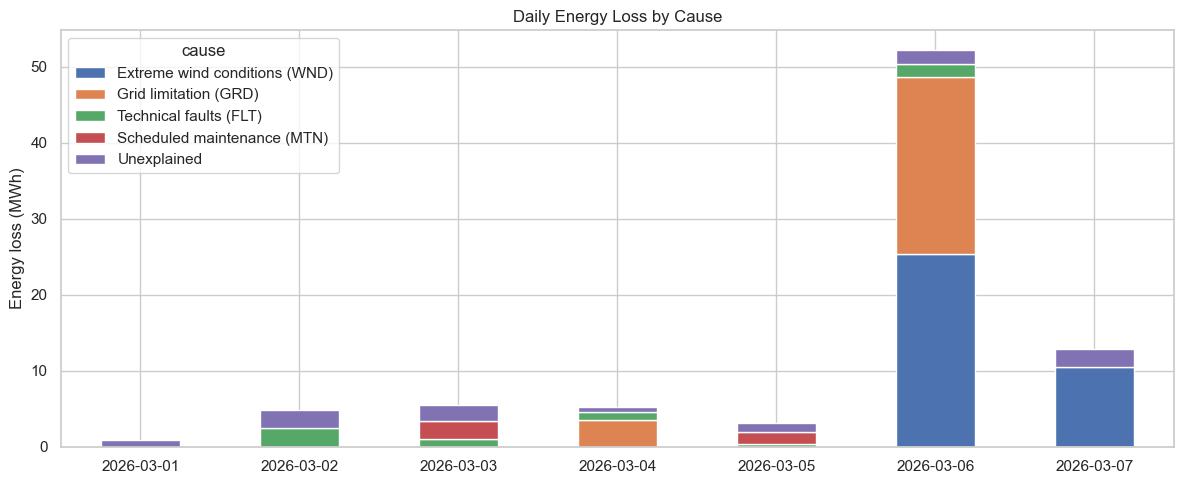

In [41]:
daily_loss = (
    turbine_weather
    .pivot_table(index=turbine_weather["timestamp"].dt.date, columns="cause",
                 values="loss_kwh", aggfunc="sum")
    .reindex(columns=CAUSE_ORDER).fillna(0)
)

ax = (daily_loss / 1000).plot(kind="bar", stacked=True, figsize=(12, 5))
ax.set(title="Daily Energy Loss by Cause", xlabel="", ylabel="Energy loss (MWh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.3 Findings

| Cause | Estimated energy loss (kWh) | Share |
|---|---:|---:|
| Extreme wind conditions (WND) | 35,786 | 42% |
| Grid limitation (GRD) | 26,952 | 32% |
| Technical faults (FLT) | 6,628 | 8% |
| Scheduled maintenance (MTN) | 3,931 | 5% |
| Unexplained | 11,360 | 13% |
| *Total* | *84,657* | 100% |

- Potential production was 727.0 MWh against 642.3 MWh actual: a **performance
  ratio of 88.4%**.
- *Three quarters of the loss came from external conditions.* WND (not recoverable;
  design cut-out) and GRD (park output limited to ~25%) together account for 74%.
  Under the alternative convention (zero expected above cut-out) the total loss
  is 48.9 MWh and WND is zero; all other categories are unchanged.
- *6 March alone accounts for ~62% of the weekly loss*: two grid limitations and
  a 3-hour high-wind shutdown on the same day.
- *Unexplained losses are almost entirely T04* (10.4 of 11.4 MWh). Unlogged derates
  on T05, T02 and T03 add 1.3 MWh. The small negative residual (−0.4 MWh) is the
  baseline's 0.07% fit error on the reference turbines, not a real gain.
- *Log corrections matter*: 3.9 MWh of GRD loss sits on records that were missing
  from the log, and 1.5 MWh of WND loss on an unlogged stop. Without the corrections
  these would appear as unexplained.

## 6. Turbine-Level Performance

### 6.1 Turbine summary

In [42]:
turbine_summary_final = (
    turbine_weather.pivot_table(index="turbine_id", columns="cause",
                                values="loss_kwh", aggfunc="sum")
    .reindex(columns=CAUSE_ORDER).fillna(0)
)
turbine_summary_final["Total loss"] = turbine_summary_final.sum(axis=1)

totals = turbine_weather.groupby("turbine_id")[["energy_kwh", "potential_kwh"]].sum()
turbine_summary_final["Performance ratio %"] = totals["energy_kwh"] / totals["potential_kwh"] * 100

normal_ops = turbine_weather[turbine_weather["label"] == ""]
normal_totals = normal_ops.groupby("turbine_id")[["energy_kwh", "expected_kwh"]].sum()
turbine_summary_final["Normal-operation ratio %"] = (
    normal_totals["energy_kwh"] / normal_totals["expected_kwh"] * 100
)

turbine_summary_final["Stop hours (FLT+MTN)"] = (
    turbine_weather[turbine_weather["label"].isin(["FLT", "MTN"])]
    .groupby("turbine_id").size().reindex(TURBINES, fill_value=0) / 6
)
turbine_summary_final = turbine_summary_final.join(
    metadata.set_index("turbine_id")["last_service_days_ago"]
)

display(turbine_summary_final.round(1))

,Extreme wind conditions (WND),Grid limitation (GRD),Technical faults (FLT),Scheduled maintenance (MTN),Unexplained,Total loss,Performance ratio %,Normal-operation ratio %,Stop hours (FLT+MTN),last_service_days_ago
turbine_id,,,,,,,,,,
T01,"5,964.30","4,460.90",364.60,0.00,-426.50,"10,363.30",91.40,100.40,1.50,12
T02,"5,964.30","4,487.70",553.60,0.00,"1,743.80","12,749.40",89.50,98.80,1.50,40
T03,"5,964.30","4,460.00","2,047.50",0.00,-713.30,"11,758.50",90.30,100.70,1.50,5
T04,"5,964.30","4,612.10","2,030.00","1,541.90","10,444.20","24,592.50",79.70,90.10,7.50,120
T05,"5,964.30","4,447.10","1,632.60",0.00,-574.40,"11,469.60",90.50,101.20,1.50,18
T06,"5,964.30","4,484.20",0.00,"2,389.30",886.00,"13,723.80",88.70,99.20,3.00,65


### 6.2 T04 diagnostic

Is T04's deficit constant across wind speeds (pointing to a power limit,
derating setting or metering issue) or wind-dependent (pointing to aerodynamic
or pitch problems)?

In [43]:
t04_normal = normal_ops[normal_ops["turbine_id"] == "T04"].copy()
t04_normal["wind_range"] = pd.cut(t04_normal["wind_speed_ms"], [3, 5, 7, 9, 11, 13, 15, 20, 25])

t04_profile = (
    t04_normal.groupby("wind_range", observed=True)
    .agg(actual_kwh=("energy_kwh", "sum"),
         expected_kwh=("expected_kwh", "sum"),
         intervals=("energy_kwh", "size"))
)
t04_profile["ratio_pct"] = t04_profile["actual_kwh"] / t04_profile["expected_kwh"] * 100
display(t04_profile.round(1))

print("Maximum 10-min output per turbine:")
display(production.groupby("turbine_id")["energy_kwh"].max().to_frame("max kWh"))

# Behaviour under an external cap (25% grid limitation, 6 March)
grid_window = turbine_weather[
    (turbine_weather["timestamp"] >= "2026-03-06 08:20") &
    (turbine_weather["timestamp"] < "2026-03-06 09:30")
]
print("Mean output during the 25% grid cap (6 Mar 08:20–09:30):")
display(grid_window.groupby("turbine_id")["energy_kwh"].mean().round(1).to_frame("kWh per 10 min"))

,actual_kwh,expected_kwh,intervals,ratio_pct
wind_range,,,,
"(3, 5]",681.20,805.40,110,84.60
"(5, 7]","4,466.80","5,025.30",172,88.90
"(7, 9]","10,246.20","11,412.60",154,89.80
"(9, 11]","19,307.30","21,383.50",149,90.30
"(11, 13]","19,770.70","21,816.80",95,90.60
"(13, 15]","12,080.40","13,413.60",54,90.10
"(15, 20]","19,265.40","21,379.30",86,90.10
"(20, 25]","9,405.40","10,427.30",42,90.20


Maximum 10-min output per turbine:


,max kWh
turbine_id,
T01,250.00
T02,246.25
T03,251.25
T04,225.00
T05,252.50
T06,247.50


Mean output during the 25% grid cap (6 Mar 08:20–09:30):


,kWh per 10 min
turbine_id,
T01,62.00
T02,61.30
T03,62.50
T04,56.10
T05,62.80
T06,61.50


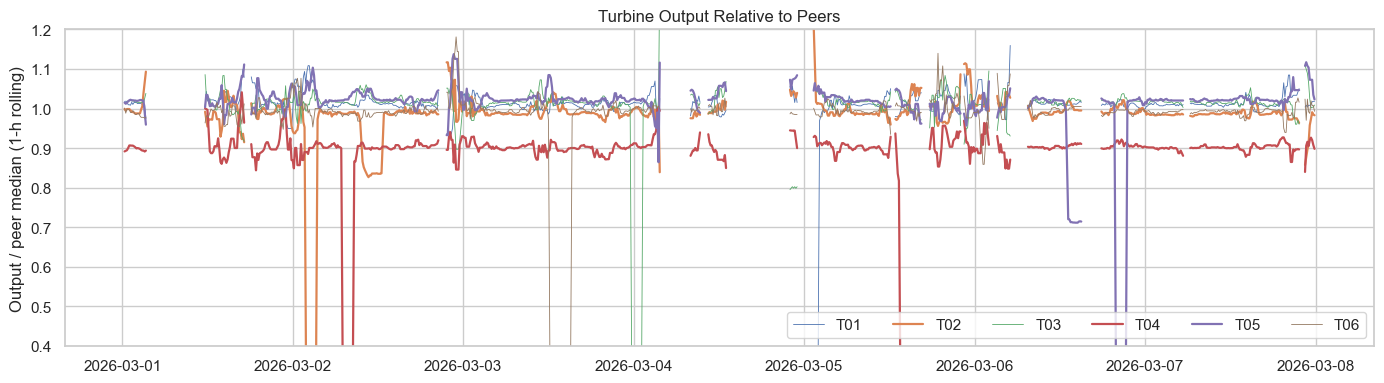

In [44]:
fig, ax = plt.subplots(figsize=(14, 4))
for t in TURBINES:
    series = ratio_to_peers[t].where(testable).rolling(6, min_periods=3).median()
    ax.plot(series.index, series,
            linewidth=1.6 if t in ["T02", "T04", "T05"] else 0.6, label=t)

ax.set(ylim=(0.4, 1.2), ylabel="Output / peer median (1-h rolling)",
       title="Turbine Output Relative to Peers")
ax.legend(ncol=6)
plt.tight_layout()
plt.show()

### 6.3 Findings

*T04 – main asset issue (performance ratio 79.7%, total loss 24.6 MWh)*
- In normal operation T04 produces **89–91% of expected output at every wind
  speed from 5 to 25 m/s**. Its maximum 10-minute output is 225 kWh, 90% of the
  ~250 kWh reached by the other turbines.
- Under the 25% grid limitation on 6 March, T04 delivered 56.1 kWh per interval
  against ~62 kWh for its peers – again 90%. A simple power cap at 225 kWh would
  not affect output under a 62.5 kWh grid limit, so the gap is a **constant
  multiplicative factor** rather than a maximum-power limit.
- A gap that does not vary with wind speed rules out typical aerodynamic or pitch
  degradation. The most likely explanations are:
  1. a *metering or signal-scaling error* (the turbine produces normally but
     records 10% less), or
  2. a *proportional derating setting* in the turbine controller.

  These can be distinguished by comparing T04's SCADA power with an independent
  meter. If it is a metering error, part of the 10.4 MWh "loss" is an accounting
  issue rather than lost energy.
- T04 also has the most stop time (7.5 h: 3 hydraulic faults and 1 maintenance)
  and the longest time since service (120 days).

*Other turbines*
- T01, T03, T05 and T06 perform at 99–101% of expected in normal operation.
- T02 performs at 98.8%; its unexplained loss (1.7 MWh) includes the 3-hour
  unlogged derate on 2 March.
- All seven fault records are hydraulic, across five of six turbines. Individually
  short, but frequent enough to justify a fleet-level review.

*Maintenance timing*
- The two maintenance events cost 3.9 MWh because they were carried out at
  moderate wind (T06: ~10 m/s, 2.4 MWh; T04: ~8 m/s, 1.5 MWh). The afternoon of
  4 March had 1–2 m/s wind, when the same work would have cost almost nothing.
  Scheduling maintenance against the wind forecast is a low-effort improvement.

In [45]:
# Brief cross-checks
daily_total = daily_loss.sum(axis=1)
print(f"6 March share of weekly loss: {daily_total.loc[pd.Timestamp('2026-03-06').date()] / daily_total.sum():.1%}")

dup = turbine_weather[(turbine_weather["turbine_id"] == "T01") &
                      (turbine_weather["timestamp"] >= "2026-03-06 21:30") &
                      (turbine_weather["timestamp"] < "2026-03-06 23:30")]
print(f"Loss that the duplicate T01 GRD record would have double-counted: {dup['loss_kwh'].sum():,.0f} kWh")

print(f"Total GRD loss: {turbine_weather.loc[turbine_weather['label'] == 'GRD', 'loss_kwh'].sum():,.0f} kWh "
      f"over {events_final[events_final['stop_code'] == 'GRD']['timestamp_start'].nunique() * 2} hours")

6 March share of weekly loss: 61.7%
Loss that the duplicate T01 GRD record would have double-counted: 1,877 kWh
Total GRD loss: 26,952 kWh over 6 hours


In [48]:
# Project directories

DATA_DIR = Path(".")
OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"

# Create output directories if they do not exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Output directory:", OUTPUT_DIR.resolve())
print("Figures directory:", FIG_DIR.resolve())

Working directory: C:\Users\marty
Output directory: C:\Users\marty\outputs
Figures directory: C:\Users\marty\outputs\figures


In [49]:
# ============================================================
# FINAL OUTPUT EXPORT
# ============================================================

# 1. Export analytical tables as individual CSV files

tables = {
    "loss_breakdown": loss_breakdown,
    "unexplained_breakdown": unexplained_breakdown,
    "data_quality_impact": data_quality_impact,
    "turbine_summary": turbine_summary_final,
    "t04_profile_by_wind_speed": t04_profile,
    "daily_loss_by_cause": daily_loss,
    "reference_power_curve": fine_curve,
    "unlogged_derates": derates,
    "events_cleaned": events_final,
    "daily_production_summary": daily_summary,
    "daily_baseline_comparison": daily_baseline
}

for name, df in tables.items():
    df.to_csv(OUTPUT_DIR / f"{name}.csv")


# 2. Export detailed interval-level attribution

interval_columns = [
    "timestamp",
    "turbine_id",
    "wind_speed_ms",
    "energy_kwh",
    "expected_kwh",
    "potential_kwh",
    "loss_kwh",
    "label",
    "inferred",
    "cause"
]

turbine_weather[interval_columns].to_csv(
    OUTPUT_DIR / "interval_level_attribution.csv",
    index=False
)


# 3. Create a consolidated Excel workbook

metrics = pd.DataFrame({
    "Metric": [
        "Actual production (kWh)",
        "Potential production (kWh)",
        "Theoretical production shortfall (kWh)",
        "Operational shortfall excluding WND cut-out (kWh)",
        "Performance ratio (%)",
        "6 March share of weekly loss (%)"
    ],
    "Value": [
        turbine_weather["energy_kwh"].sum(),
        turbine_weather["potential_kwh"].sum(),
        turbine_weather["loss_kwh"].sum(),
        loss_breakdown.loc[
            "Total", "Alternative: zero above cut-out (kWh)"
        ],
        turbine_weather["energy_kwh"].sum()
        / turbine_weather["potential_kwh"].sum() * 100,
        daily_loss.loc[
            pd.Timestamp("2026-03-06").date()
        ].sum() / daily_loss.sum().sum() * 100
    ]
})

with pd.ExcelWriter(
    OUTPUT_DIR / "alphawind_analysis_summary.xlsx",
    engine="openpyxl"
) as writer:

    metrics.to_excel(
        writer, sheet_name="Key metrics", index=False
    )

    for name, df in tables.items():
        df.to_excel(
            writer,
            sheet_name=name[:31]
        )


# 4. Save presentation-ready figures

# Reference power curve and T04
xs = np.linspace(0, 25, 500)

t04_obs = turbine_weather[
    (turbine_weather["turbine_id"] == "T04") &
    (turbine_weather["label"] == "")
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    reference_clean["wind_speed_ms"],
    reference_clean["energy_kwh"],
    s=5,
    alpha=0.3,
    label="Reference turbines"
)

ax.scatter(
    t04_obs["wind_speed_ms"],
    t04_obs["energy_kwh"],
    s=5,
    alpha=0.4,
    label="T04"
)

ax.plot(
    xs,
    expected_from_curve(xs),
    linewidth=2.5,
    label="Reference power curve"
)

ax.set(
    xlabel="Wind speed (m/s)",
    ylabel="Energy per 10 minutes (kWh)",
    title="Reference Power Curve and T04 Performance"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    FIG_DIR / "power_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)


# Daily energy loss by cause
ax = (daily_loss / 1000).plot(
    kind="bar",
    stacked=True,
    figsize=(12, 5)
)

ax.set(
    title="Daily Energy Loss by Cause",
    xlabel="Date",
    ylabel="Energy loss (MWh)"
)

plt.xticks(rotation=0)
ax.figure.tight_layout()

ax.figure.savefig(
    FIG_DIR / "daily_loss_by_cause.png",
    dpi=200,
    bbox_inches="tight"
)

plt.close(ax.figure)


# Actual versus potential production
park_ts = turbine_weather.groupby("timestamp")[
    ["potential_kwh", "energy_kwh"]
].sum()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    park_ts.index,
    park_ts["potential_kwh"],
    label="Potential production",
    linewidth=1
)

ax.plot(
    park_ts.index,
    park_ts["energy_kwh"],
    label="Actual production",
    linewidth=1
)

ax.set(
    title="Actual vs Potential Park Production",
    xlabel="Timestamp",
    ylabel="Energy per 10 minutes (kWh)"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    FIG_DIR / "park_actual_vs_potential.png",
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)


# Turbine performance relative to peers
fig, ax = plt.subplots(figsize=(14, 5))

for t in TURBINES:
    series = (
        ratio_to_peers[t]
        .where(testable)
        .rolling(6, min_periods=3)
        .median()
    )

    ax.plot(
        series.index,
        series,
        linewidth=1.5 if t == "T04" else 0.8,
        label=t
    )

ax.set(
    title="Turbine Production Relative to Peers",
    xlabel="Timestamp",
    ylabel="Output / peer median",
    ylim=(0.4, 1.2)
)

ax.legend(ncol=6)
fig.tight_layout()

fig.savefig(
    FIG_DIR / "turbine_ratio_to_peers.png",
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)


# 5. Confirm exported files

print("Export completed successfully.\n")

for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(file.relative_to(OUTPUT_DIR))

Export completed successfully.

alphawind_analysis_summary.xlsx
daily_baseline_comparison.csv
daily_loss_by_cause.csv
daily_production_summary.csv
data_quality_impact.csv
events_cleaned.csv
figures\daily_loss_by_cause.png
figures\park_actual_vs_potential.png
figures\power_curve.png
figures\turbine_ratio_to_peers.png
interval_level_attribution.csv
loss_breakdown.csv
reference_power_curve.csv
t04_profile_by_wind_speed.csv
turbine_summary.csv
unexplained_breakdown.csv
unlogged_derates.csv
